# Para-procesimi i të dhënave · London Airbnb

Ky notebook bashkon katër pjesët e projektit në rendin e tyre: inspektimi dhe kualiteti, pastrimi dhe integrimi, krijimi i vetive, transformimi dhe reduktimi i dimensionit. Ekzekutoni qelizat nga fillimi në fund me kernel-in e mjedisit `.venv`. Para ekzekutimit, vendosni `listings.csv.gz`, `reviews.csv.gz` dhe `calendar.csv.gz` në dosjen `dataset/` siç përshkruhet në README.

*Rezultatet e ruajtura më poshtë janë marrë nga katër notebook-et burimore; ato nuk janë rillogaritur gjatë bashkimit.*

# London Airbnb Dataset

**Faza I · Notebook 01 — Inspektimi fillestar**

Si ndryshon çmimi për natë sipas vendndodhjes, llojit të dhomës dhe kapacitetit? Para se t’i analizojmë këto lidhje, duhet të kuptojmë strukturën e të dhënave dhe kufizimet e tyre.

Përdorim listimet e Londrës nga **Inside Airbnb**, snapshot-i i datës **17 shtator 2026**. Çdo rresht përfaqëson një listim; kolonat përshkruajnë pronën, pronarin, disponueshmërinë, komentet dhe çmimin.

Në këtë notebook shqyrtojmë strukturën dhe tipet e kolonave, vlerat që mungojnë dhe dublikatat, fjalorin e të dhënave, tri metoda mostrimi dhe agregimet kryesore. Në fund përmbledhim anomalitë që udhëheqin vendimet e pastrimit në notebook-un 02.


## 1. Leximi i dataset-it

Lexojmë skedarin lokal me Pandas. Rrugët relative funksionojnë nga dosja e projektit ose nga `notebooks/`. 

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_PATH = ROOT / "dataset" / "listings.csv.gz"
raw = pd.read_csv(DATA_PATH, low_memory=False)
raw.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,11551,https://www.airbnb.com/rooms/11551,20260917015706,2026-09-19,NaN,Artistic London Pied-à-Terre,Live like a local in this quintessential Londo...,NaN,https://a0.muscache.com/pictures/prohost-api/H...,43039,...,4.84,4.54,4.49,NaN,NaN,1,1,0,0,0.98
1,13913,https://www.airbnb.com/rooms/13913,20260917015706,2026-09-19,NaN,Holiday London DB Room Let-on going,My bright double bedroom with a large window h...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,54730,...,4.88,4.79,4.79,NaN,NaN,2,1,1,0,0.29
2,15400,https://www.airbnb.com/rooms/15400,20260917015706,2026-09-19,NaN,Bright Chelsea Apartment. Chelsea!,Lots of windows and light. St Luke's Gardens ...,NaN,https://a0.muscache.com/pictures/428392/462d26...,60302,...,4.84,4.94,4.74,NaN,NaN,1,1,0,0,0.48
3,24328,https://www.airbnb.com/rooms/24328,20260917015706,2026-09-19,NaN,Battersea live/work artist house with car park,"Artist house by SW Battersea Park, bright high...",NaN,https://a0.muscache.com/pictures/9194b40f-c627...,41759,...,4.93,4.60,4.66,NaN,NaN,1,1,0,0,0.50
4,25081,https://www.airbnb.com/rooms/25081,20260917015706,2026-09-21,previous scrape,Lovely bright flat for 1-4p 20 m to Covent Garden,"<b>The space</b><br />Big, charming flat in We...",NaN,https://a0.muscache.com/pictures/hosting/Hosti...,72242,...,NaN,NaN,NaN,NaN,NaN,1,1,0,0,NaN


### Madhësia dhe kolonat

Një rresht përfaqëson një listim. Shfaqim numrin e rreshtave dhe të kolonave, pastaj emrat e të gjitha kolonave.

In [2]:
print(f"Madhësia e dataset-it: {raw.shape}")

Madhësia e dataset-it: (91954, 90)


In [3]:
import numpy as np

display(pd.DataFrame(np.array_split(raw.columns, 5)).T)

,0,1,2,3,4
0,id,hosts_time_as_host_months,latitude,minimum_minimum_nights,estimated_occupancy_l365d
1,listing_url,host_location,longitude,maximum_minimum_nights,estimated_revenue_l365d
2,scrape_id,host_about,property_type,minimum_maximum_nights,first_review
3,last_scraped,host_response_time,room_type,maximum_maximum_nights,last_review
4,source,host_response_rate,accommodates,minimum_nights_avg_ntm,review_scores_rating
5,name,host_acceptance_rate,bathrooms,maximum_nights_avg_ntm,review_scores_accuracy
6,description,host_is_superhost,bathrooms_text,calendar_updated,review_scores_cleanliness
7,neighborhood_overview,host_thumbnail_url,bedrooms,has_availability,review_scores_checkin
8,picture_url,host_picture_url,beds,availability_30,review_scores_communication
9,host_id,host_neighbourhood,amenities,availability_60,review_scores_location


### Kontroll i thjeshtë i vendndodhjes

Gjerësia gjeografike e Londrës është rreth 51.5°. Ky është vetëm një kontroll orientues; nuk vërteton burimin ose versionin e dataset-it.

In [4]:
latitude = raw["latitude"].median()
if 51 < latitude < 52:
    print(f"Median latitude {latitude:.2f}: consistent with London.")
else:
    print(f"WARNING: median latitude {latitude:.2f}; check the dataset location.")

Median latitude 51.51: consistent with London.


### Tipet e kolonave

Për secilën kolonë shfaqim tipin që ka lexuar Pandas dhe një vlerë shembull. Grafiku tregon sa kolona ka për secilin tip teknik. Disa fusha, si `price` dhe datat, lexohen si tekst dhe konvertohen gjatë pastrimit.


In [5]:
data_dictionary = pd.DataFrame({
    "Tipi_Pandas": raw.dtypes.astype(str),
    "Shembull_vlere": [
        raw[col].dropna().iloc[0] if raw[col].notna().any() else None
        for col in raw.columns
    ],
})
display(data_dictionary)


,Tipi_Pandas,Shembull_vlere
id,int64,11551
listing_url,object,https://www.airbnb.com/rooms/11551
scrape_id,int64,20260917015706
last_scraped,object,2026-09-19
source,object,previous scrape
...,...,...
calculated_host_listings_count,int64,1
calculated_host_listings_count_entire_homes,int64,1
calculated_host_listings_count_private_rooms,int64,0
calculated_host_listings_count_shared_rooms,int64,0


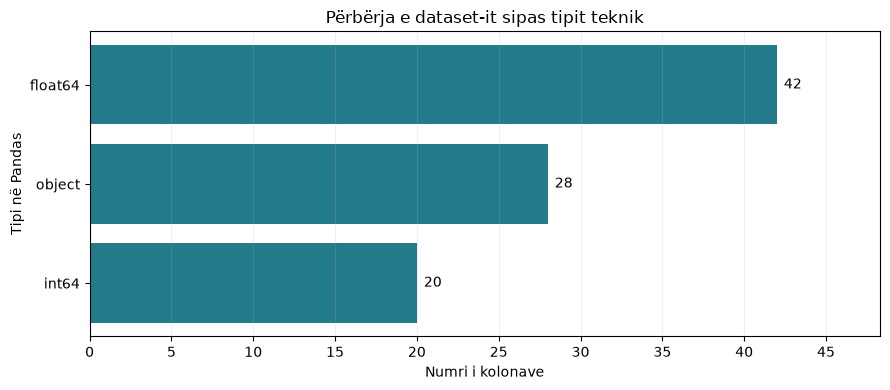

In [6]:
tipet = raw.dtypes.astype(str).value_counts().sort_values()
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(tipet.index, tipet.values, color="#237A8A")
ax.bar_label(ax.containers[0], padding=5, fmt="%d")
ax.set(title="Përbërja e dataset-it sipas tipit teknik", xlabel="Numri i kolonave", ylabel="Tipi në Pandas")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.margins(x=0.15)
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
plt.show()


### Tipet e atributeve sipas kuptimit

Kolonat i klasifikojmë sipas katër shkallëve të matjes:

| Tipi | Çfarë ka kuptim? | Shembull në dataset |
|---|---|---|
| **Nominal** | Të kontrollojmë nëse dy vlera janë të njëjta apo të ndryshme. | `id`, `room_type`, `instant_bookable` |
| **Ordinal** | Të renditim vlerat. | `review_scores_rating` |
| **Interval** | Të llogarisim diferencën mes vlerave. | `last_scraped`, `latitude` |
| **Ratio** | Të llogarisim diferencën dhe raportin, p.sh. "dy herë më shumë". | `price`, `beds`, `number_of_reviews` |

Teksti i lirë dhe listat, si `description` dhe `amenities`, shënohen **Nuk aplikohet (tekst/listë)**. Klasifikimi i kolonave bosh bazohet në kuptimin e pritur të fushës.


In [7]:
def cakto_tipin_e_atributit(kolona):
    emri = kolona.lower()

    if emri in ["description", "neighborhood_overview", "host_about", "name",
                "amenities", "host_verifications", "bathrooms_text", "price_quote_raw"]:
        return "Nuk aplikohet (tekst/listë)"

    if emri.startswith("review_scores_") or emri == "host_response_time":
        return "Ordinal"
    if (
        emri in ["latitude", "longitude", "first_review", "last_review",
                 "last_scraped", "calendar_last_scraped"]
        or "date" in emri
        or emri.endswith("_since")
    ):
        return "Interval"

    if emri in [
        "price", "weekly_price", "monthly_price", "security_deposit", "cleaning_fee",
        "extra_people", "host_listings_count", "host_total_listings_count",
        "accommodates", "bedrooms", "beds", "bathrooms", "reviews_per_month",
        "host_response_rate", "host_acceptance_rate"
    ] or emri.startswith((
        "calculated_host_listings_count", "availability_", "number_of_reviews",
        "minimum_", "maximum_", "hosts_time_as_", "estimated_",
        "price_quote_total_", "price_quote_price_per_"
    )):
        return "Ratio"
    return "Nominal"



data_dictionary["Tipi_atributit"] = data_dictionary.index.to_series().apply(cakto_tipin_e_atributit)

display(data_dictionary[["Tipi_Pandas", "Tipi_atributit", "Shembull_vlere"]])

print("Numri i kolonave në tabelë:", len(data_dictionary))
print("Numri i kolonave në dataset:", len(raw.columns))

,Tipi_Pandas,Tipi_atributit,Shembull_vlere
id,int64,Nominal,11551
listing_url,object,Nominal,https://www.airbnb.com/rooms/11551
scrape_id,int64,Nominal,20260917015706
last_scraped,object,Interval,2026-09-19
source,object,Nominal,previous scrape
...,...,...,...
calculated_host_listings_count,int64,Ratio,1
calculated_host_listings_count_entire_homes,int64,Ratio,1
calculated_host_listings_count_private_rooms,int64,Ratio,0
calculated_host_listings_count_shared_rooms,int64,Ratio,0


Numri i kolonave në tabelë: 90
Numri i kolonave në dataset: 90


### Statistikat përshkruese

`describe(include="all")` përmbledh kolonat numerike dhe tekstuale. `.T` e kthen tabelën në mënyrë që secila kolonë e dataset-it të paraqitet si rresht. `count` numëron vetëm vlerat jo boshe.

In [8]:
raw.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,91954.0,NaN,NaN,NaN,854262404361834624.0,677082041263102592.0,11551.0,36091144.25,1005134507493807872.0,1479246812655930624.0,1776301274055096832.0
listing_url,91954,91954,https://www.airbnb.com/rooms/11551,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
scrape_id,91954.0,NaN,NaN,NaN,20260917015706.0,0.0,20260917015706.0,20260917015706.0,20260917015706.0,20260917015706.0,20260917015706.0
last_scraped,91954,6,2026-09-19,22635,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source,32311,1,previous scrape,32311,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
calculated_host_listings_count,91954.0,NaN,NaN,NaN,16.256498,47.919251,1.0,1.0,2.0,9.0,501.0
calculated_host_listings_count_entire_homes,91954.0,NaN,NaN,NaN,13.774387,46.836692,0.0,0.0,1.0,6.0,500.0
calculated_host_listings_count_private_rooms,91954.0,NaN,NaN,NaN,2.296605,9.810881,0.0,0.0,0.0,1.0,141.0
calculated_host_listings_count_shared_rooms,91954.0,NaN,NaN,NaN,0.028851,0.663465,0.0,0.0,0.0,0.0,25.0


## 2. Vlerat që mungojnë dhe dublikatat

Kontrollojmë sa të dhëna mungojnë dhe nëse ka rreshta ose ID listimesh të përsëritura. Këtu vetëm i numërojmë; të dhënat origjinale mbeten të pandryshuara.

### Sa vlera mungojnë?

`isna()` gjen qelizat boshe. `sum()` i numëron ato për çdo kolonë.

In [9]:
missing_counts = raw.isna().sum()

print("Qeliza boshe:", int(missing_counts.sum()))
print("Kolona me vlera boshe:", int((missing_counts > 0).sum()))
print("Kolona plotësisht boshe:", int((missing_counts == len(raw)).sum()))

Qeliza boshe: 1933263
Kolona me vlera boshe: 51
Kolona plotësisht boshe: 15


### Cilat kolona kanë më shumë mungesa?

Tabela tregon numrin dhe përqindjen e mungesave për çdo kolonë.

In [10]:
missing_table = pd.DataFrame({
    "missing_count": missing_counts,
    "missing_percentage": (missing_counts / len(raw) * 100).round(2)
})
missing_table.sort_values("missing_count", ascending=False)


,missing_count,missing_percentage
neighborhood_overview,91954,100.0
host_since,91954,100.0
host_response_time,91954,100.0
host_thumbnail_url,91954,100.0
host_acceptance_rate,91954,100.0
...,...,...
availability_30,0,0.0
calculated_host_listings_count,0,0.0
calculated_host_listings_count_entire_homes,0,0.0
calculated_host_listings_count_private_rooms,0,0.0


### Mungesat më të mëdha në grafik

Grafiku tregon 25 kolonat me përqindjen më të lartë të vlerave që mungojnë. Përqindja lejon krahasim të drejtpërdrejtë mes kolonave.


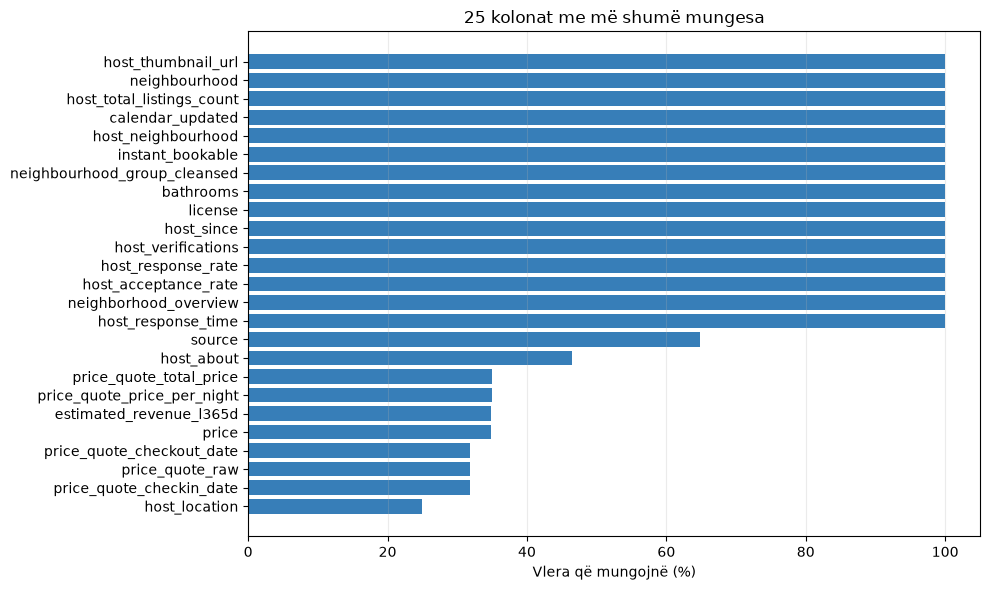

In [11]:
import matplotlib.pyplot as plt

mungesat_kryesore = missing_table.sort_values(
    "missing_percentage", ascending=False
).head(25).sort_values("missing_percentage")

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(mungesat_kryesore.index, mungesat_kryesore["missing_percentage"], color="#377eb8")
ax.set(xlabel="Vlera që mungojnë (%)", title="25 kolonat me më shumë mungesa", xlim=(0, 105))
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()


### Dublikatat

Një rresht identik përsërit të gjitha vlerat. Një ID e përsëritur tregon se i njëjti identifikues listimi shfaqet më shumë se një herë.

In [12]:
print("Rreshta identikë:", int(raw.duplicated().sum()))
print("ID listimesh të përsëritura:", int(raw["id"].duplicated().sum()))

Rreshta identikë: 0
ID listimesh të përsëritura: 0


## 3. Mostrimi (Sampling)

Krahasojmë tri metoda: mostrimin e rastësishëm, të shtresëzuar sipas llojit të dhomës dhe sistematik. Përdorim 10% të të dhënave.

### 3.1 Mostër e rastësishme (Simple Random Sampling)

In [13]:
# Zgjedhim 10% të listimeve në mënyrë të rastësishme
sample_random = raw.sample(frac=0.10, random_state=42)

print("Madhësia e dataset-it:", len(raw))
print("Madhësia e mostrës së rastësishme:", len(sample_random))
display(sample_random.head())

Madhësia e dataset-it: 91954
Madhësia e mostrës së rastësishme: 9195


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
87559,1728912045068148599,https://www.airbnb.com/rooms/1728912045068148599,20260917015706,2026-09-19,NaN,London Base | 7 Beds | Parking | Liverpool Street,✪Long Stay Discounts Available✪<br /><br />✪ 4...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,483035482,...,NaN,NaN,NaN,NaN,NaN,10,10,0,0,NaN
73998,1564527722987559364,https://www.airbnb.com/rooms/1564527722987559364,20260917015706,2026-09-20,NaN,Cosy small room central London,It is a family flat situated in the third floo...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,10205769,...,5.00,4.67,4.83,NaN,NaN,2,0,2,0,0.69
67070,1449418450413890805,https://www.airbnb.com/rooms/1449418450413890805,20260917015706,2026-09-19,NaN,Spacious 4BR Home|Sleeps 7|5 min to Shadwell w...,Bright and spacious 4-bedroom home in a quiet ...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,139158577,...,5.00,4.86,4.68,NaN,NaN,2,2,0,0,2.56
47669,1030454236977505897,https://www.airbnb.com/rooms/1030454236977505897,20260917015706,2026-09-19,NaN,Entire flat with Balcony,Forget your worries in this spacious and seren...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,546053630,...,NaN,NaN,NaN,NaN,NaN,1,0,1,0,NaN
21270,32322018,https://www.airbnb.com/rooms/32322018,20260917015706,2026-09-21,NaN,Radiant Kensington Studio,Stunning studio located on the Third Floor of ...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,226472167,...,4.92,4.96,4.66,NaN,NaN,28,28,0,0,3.26


### 3.2 Mostër e shtresëzuar (Stratified Sampling)

Zgjedhim 10% nga secili grup i `room_type`, që edhe grupet e vogla të përfaqësohen në mostër.

In [14]:
if "room_type" in raw.columns:
    sample_stratified = (
        raw.groupby("room_type", group_keys=False)
           .sample(frac=0.10, random_state=42)
    )

    print("Madhësia e mostrës së shtresëzuar:", len(sample_stratified))
    display(sample_stratified["room_type"].value_counts().to_frame("Numri në mostër"))

Madhësia e mostrës së shtresëzuar: 9195


,Numri në mostër
room_type,
Entire home/apt,6107
Private room,3047
Hotel room,21
Shared room,20


### 3.3 Mostër sistematike (Systematic Sampling)

Zgjedhim çdo rresht të dhjetë pasi dataset-i është renditur në formën e tij aktuale.

In [15]:
k = 10
sample_systematic = raw.iloc[::k].copy()

print("Madhësia e mostrës sistematike:", len(sample_systematic))
display(sample_systematic.head())

Madhësia e mostrës sistematike: 9196


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,11551,https://www.airbnb.com/rooms/11551,20260917015706,2026-09-19,NaN,Artistic London Pied-à-Terre,Live like a local in this quintessential Londo...,NaN,https://a0.muscache.com/pictures/prohost-api/H...,43039,...,4.84,4.54,4.49,NaN,NaN,1,1,0,0,0.98
10,2889261,https://www.airbnb.com/rooms/2889261,20260917015706,2026-09-19,NaN,MAGICAL URBAN RETREAT sleep up to 5,"A perfect urban retreat, finished to an inspir...",NaN,https://a0.muscache.com/pictures/37330137/16da...,1616720,...,4.97,4.71,4.73,NaN,NaN,21,21,0,0,0.81
20,2906069,https://www.airbnb.com/rooms/2906069,20260917015706,2026-09-21,previous scrape,Bright two-bedroom flat with great transport l...,Spacious airy 2-bedroom apartment in Camberwel...,NaN,https://a0.muscache.com/pictures/97239148/49b3...,3162609,...,4.93,4.69,4.80,NaN,NaN,1,1,0,0,0.27
30,45163,https://www.airbnb.com/rooms/45163,20260917015706,2026-09-19,NaN,Room with a garden,Nice room in house in the West Hampstead area ...,NaN,https://a0.muscache.com/pictures/ec999674-6b16...,199530,...,5.00,5.00,4.00,NaN,NaN,1,0,1,0,0.02
40,2936993,https://www.airbnb.com/rooms/2936993,20260917015706,2026-09-21,previous scrape,Stylish Hackney home - double room,"Newly refurbished, my split-level flat is styl...",NaN,https://a0.muscache.com/pictures/87451462/ca67...,3928128,...,4.89,4.78,4.78,NaN,NaN,1,1,0,0,0.07


### 3.4 Krahasimi i mostrave

Krahasojmë përqindjen e llojeve të dhomave, çmimin median dhe përfaqësimin e zonave administrative të Londrës (borough).

In [16]:
def permbledh_mostren(df, emri):
    rezultat = {"Mostra": emri, "Numri i listimeve": len(df)}

    if "price" in df.columns:
        cmimi = pd.to_numeric(
            df["price"].astype(str).str.replace("$", "", regex=False).str.replace(",", "", regex=False),
            errors="coerce"
        )
        rezultat["Çmimi median"] = cmimi.median()

    if "room_type" in df.columns:
        rezultat["Lloje dhomash"] = df["room_type"].nunique()

    if "neighbourhood_cleansed" in df.columns:
        rezultat["Borough të përfaqësuara"] = df["neighbourhood_cleansed"].nunique()

    return rezultat

krahasimi_mostrave = pd.DataFrame([
    permbledh_mostren(raw, "Dataseti origjinal"),
    permbledh_mostren(sample_random, "Rastësore"),
    permbledh_mostren(sample_stratified, "Shtresëzuar") if "room_type" in raw.columns else permbledh_mostren(sample_random, "Shtresëzuar"),
    permbledh_mostren(sample_systematic, "Sistematike")
])

display(krahasimi_mostrave.round(2))

# Përqindja e llojeve të dhomave në dataset-in origjinal dhe në secilën mostër
if "room_type" in raw.columns:
    perqindjet_dhomave = pd.DataFrame({
        "Origjinali (%)": raw["room_type"].value_counts(normalize=True) * 100,
        "Rastësore (%)": sample_random["room_type"].value_counts(normalize=True) * 100,
        "Shtresëzuar (%)": sample_stratified["room_type"].value_counts(normalize=True) * 100,
        "Sistematike (%)": sample_systematic["room_type"].value_counts(normalize=True) * 100
    }).fillna(0).round(2)

    display(perqindjet_dhomave)

,Mostra,Numri i listimeve,Çmimi median,Lloje dhomash,Borough të përfaqësuara
0,Dataseti origjinal,91954,175.00,4,33
1,Rastësore,9195,173.26,4,33
2,Shtresëzuar,9195,174.00,4,33
3,Sistematike,9196,173.00,4,33


,Origjinali (%),Rastësore (%),Shtresëzuar (%),Sistematike (%)
room_type,,,,
Entire home/apt,66.42,66.16,66.42,66.71
Hotel room,0.23,0.24,0.23,0.22
Private room,33.14,33.31,33.14,32.88
Shared room,0.22,0.29,0.22,0.18


### Përfaqësimi i llojeve të dhomave në mostra

Shtyllat krahasojnë përqindjen e çdo lloji dhome në dataset-in origjinal dhe në tri mostrat. Një mostër përfaqësuese ka përqindje të afërta me origjinalin.


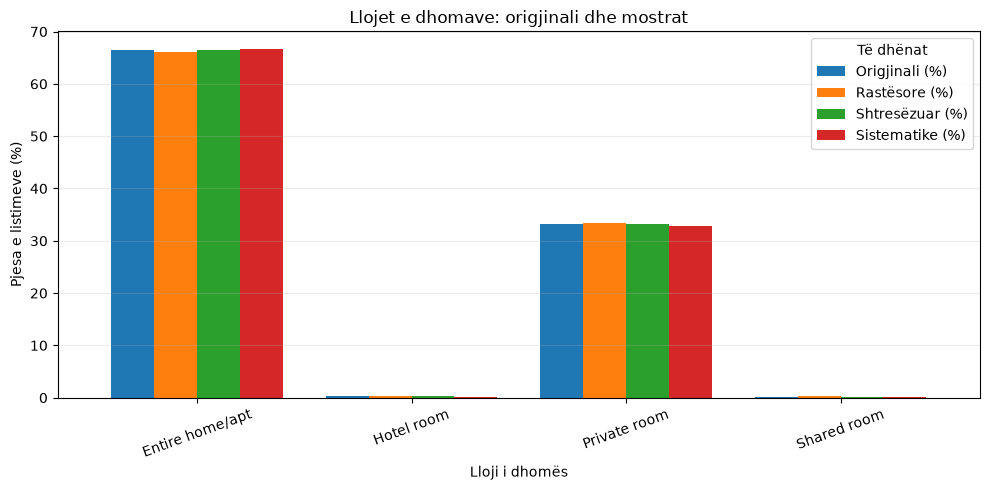

In [17]:
if "room_type" in raw.columns:
    ax = perqindjet_dhomave.plot.bar(figsize=(10, 5), width=0.8)
    ax.set(xlabel="Lloji i dhomës", ylabel="Pjesa e listimeve (%)",
           title="Llojet e dhomave: origjinali dhe mostrat")
    ax.tick_params(axis="x", rotation=20)
    ax.legend(title="Të dhënat")
    ax.grid(axis="y", alpha=0.25)
    ax.figure.tight_layout()
    plt.show()


### 3.5 Kontrolli i shpërndarjes së zonave dhe çmimeve

Përveç përqindjeve të llojeve të dhomave, kontrollojmë nëse mostrat ruajnë edhe shpërndarjen sipas zonave dhe çmimeve.

In [18]:
print('Shpërndarja e zonave')
# Krahasimi i zonave administrative në dataset dhe në mostra
if "neighbourhood_cleansed" in raw.columns:
    borough_distribution = pd.DataFrame({
        "Origjinali (%)": raw["neighbourhood_cleansed"].value_counts(normalize=True) * 100,
        "Rastësore (%)": sample_random["neighbourhood_cleansed"].value_counts(normalize=True) * 100,
        "Shtresëzuar (%)": sample_stratified["neighbourhood_cleansed"].value_counts(normalize=True) * 100,
        "Sistematike (%)": sample_systematic["neighbourhood_cleansed"].value_counts(normalize=True) * 100
    }).fillna(0).round(2)

    display(borough_distribution.head(15))
    
print('Shpërndarja e çmimeve')
# Krahasimi i çmimeve me disa statistika të thjeshta
def statistika_cmimit(df, emri):
    cmimi = pd.to_numeric(
        df["price"].astype(str).str.replace("$", "", regex=False).str.replace(",", "", regex=False),
        errors="coerce"
    )
    return {
        "Mostra": emri,
        "Numri i çmimeve të vlefshme": cmimi.notna().sum(),
        "Çmimi median": cmimi.median(),
        "Çmimi mesatar": cmimi.mean(),
        "Çmimi P90": cmimi.quantile(0.90)
    }

krahasimi_cmimit = pd.DataFrame([
    statistika_cmimit(raw, "Origjinali"),
    statistika_cmimit(sample_random, "Rastësore"),
    statistika_cmimit(sample_stratified, "Shtresëzuar"),
    statistika_cmimit(sample_systematic, "Sistematike")
])

display(krahasimi_cmimit.round(2))

Shpërndarja e zonave


,Origjinali (%),Rastësore (%),Shtresëzuar (%),Sistematike (%)
neighbourhood_cleansed,,,,
Barking and Dagenham,0.74,0.66,0.77,0.89
Barnet,2.53,2.64,2.14,2.60
Bexley,0.65,0.50,0.60,0.65
Brent,3.16,3.33,3.10,3.40
Bromley,0.99,0.96,0.90,1.01
Camden,6.72,6.45,6.87,6.39
City of London,0.70,0.59,0.76,0.77
Croydon,1.84,1.79,1.72,1.89
Ealing,2.54,2.37,2.79,2.31


Shpërndarja e çmimeve


,Mostra,Numri i çmimeve të vlefshme,Çmimi median,Çmimi mesatar,Çmimi P90
0,Origjinali,59905,175.00,248.35,445.00
1,Rastësore,5915,173.26,240.39,438.00
2,Shtresëzuar,5949,174.00,249.11,447.08
3,Sistematike,5959,173.00,255.01,444.04


### Krahasimi i zonave mes mostrave

Grafiku krahason 10 zonat me përqindjen më të lartë në dataset-in origjinal. Për secilën zonë, shtyllat tregojnë sa afër origjinalit është secila mostër.


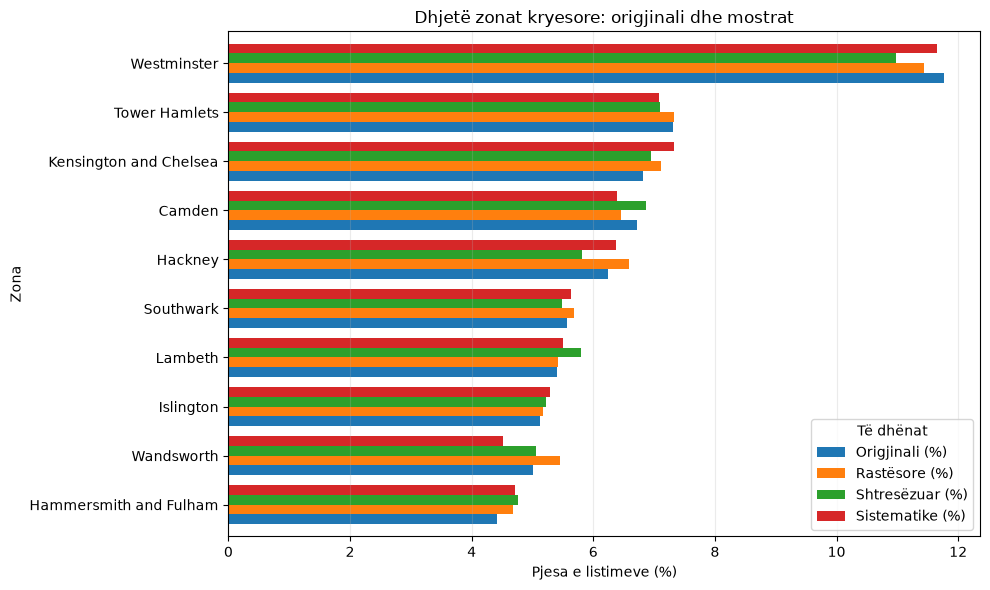

In [19]:
if "neighbourhood_cleansed" in raw.columns and not borough_distribution.empty:
    zonat = borough_distribution.nlargest(10, "Origjinali (%)")
    ax = zonat.iloc[::-1].plot.barh(figsize=(10, 6), width=0.8)
    ax.set(xlabel="Pjesa e listimeve (%)", ylabel="Zona",
           title="Dhjetë zonat kryesore: origjinali dhe mostrat")
    ax.legend(title="Të dhënat", loc="lower right")
    ax.grid(axis="x", alpha=0.25)
    ax.figure.tight_layout()
    plt.show()


## 4. Agregimi (Aggregation)

Krijojmë tabela përmbledhëse me numrin e listimeve, çmimin median dhe pjesën e listimeve. Çmimi konvertohet nga tekst në numër para llogaritjes.

In [20]:
# Kthejmë kolonën price në vlera numerike për llogaritje
if "price" in raw.columns:
    raw["price_numeric"] = pd.to_numeric(
        raw["price"].astype(str).str.replace("$", "", regex=False).str.replace(",", "", regex=False),
        errors="coerce"
    )

    print("Shembuj të çmimeve të konvertuara:")
    display(raw[["price", "price_numeric"]].head())

Shembuj të çmimeve të konvertuara:


,price,price_numeric
0,$267.50,267.5
1,$127.00,127.0
2,$137.50,137.5
3,$228.00,228.0
4,NaN,NaN


### Shpërndarja e çmimeve

Histogrami tregon ku përqendrohen çmimet. Pamja kufizohet te percentili i 99-të; çmimet më të larta mbeten në dataset.


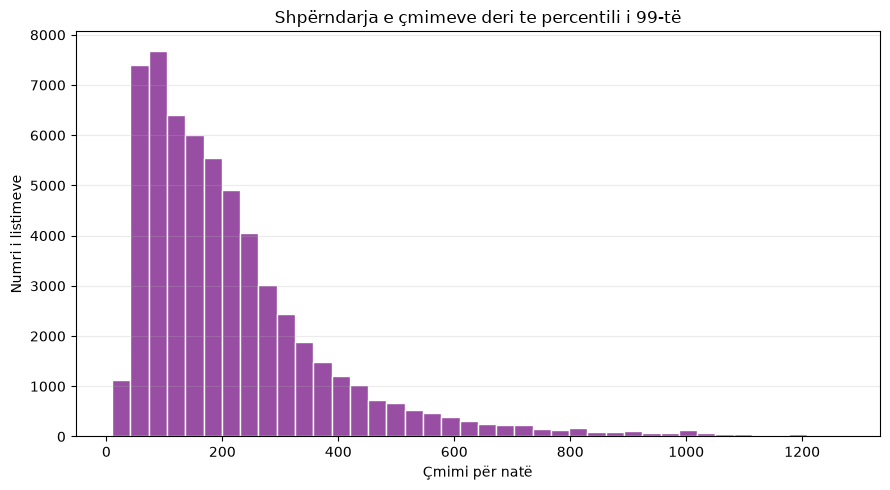

In [21]:
if "price_numeric" in raw.columns:
    cmimet = raw["price_numeric"].dropna()
    cmimet = cmimet[cmimet >= 0]
    if not cmimet.empty:
        kufiri_99 = cmimet.quantile(0.99)
        fig, ax = plt.subplots(figsize=(9, 5))
        ax.hist(cmimet[cmimet <= kufiri_99], bins=40, color="#984ea3", edgecolor="white")
        ax.set(xlabel="Çmimi për natë", ylabel="Numri i listimeve", title="Shpërndarja e çmimeve deri te percentili i 99-të")
        ax.grid(axis="y", alpha=0.25)
        fig.tight_layout()
        plt.show()


### 4.1 Agregimi sipas zonës

In [22]:
borough_col = "neighbourhood_cleansed"

if borough_col in raw.columns:
    agregimi_borough = raw.groupby(borough_col).agg(
        numri_listimeve=("id", "count"),
        cmimi_median=("price_numeric", "median")
    ).reset_index()

    agregimi_borough["perqindja_%"] = (
        agregimi_borough["numri_listimeve"] / len(raw) * 100
    ).round(2)

    agregimi_borough = agregimi_borough.sort_values("numri_listimeve", ascending=False)
    display(agregimi_borough.head(10))

,neighbourhood_cleansed,numri_listimeve,cmimi_median,perqindja_%
32,Westminster,10825,282.000,11.77
29,Tower Hamlets,6723,161.500,7.31
19,Kensington and Chelsea,6271,273.180,6.82
5,Camden,6178,207.670,6.72
11,Hackney,5740,164.465,6.24
27,Southwark,5126,158.000,5.57
21,Lambeth,4968,153.200,5.40
18,Islington,4707,182.000,5.12
31,Wandsworth,4611,185.210,5.01
12,Hammersmith and Fulham,4065,184.000,4.42


### 4.2 Agregimi sipas `room_type`

In [23]:
if "room_type" in raw.columns:
    agregimi_room_type = raw.groupby("room_type").agg(
        numri_listimeve=("id", "count"),
        cmimi_median=("price_numeric", "median")
    ).reset_index()

    agregimi_room_type["perqindja_%"] = (
        agregimi_room_type["numri_listimeve"] / len(raw) * 100
    ).round(2)

    display(agregimi_room_type.sort_values("numri_listimeve", ascending=False))

,room_type,numri_listimeve,cmimi_median,perqindja_%
0,Entire home/apt,61074,227.0,66.42
2,Private room,30471,80.0,33.14
1,Hotel room,207,187.5,0.23
3,Shared room,202,36.0,0.22


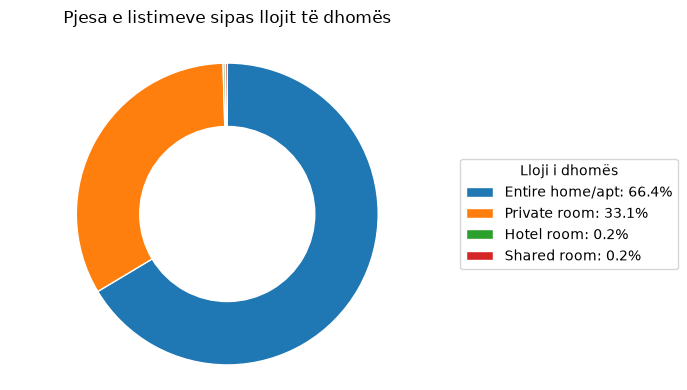

In [24]:
if "room_type" in raw.columns and not agregimi_room_type.empty:
    pjeset = agregimi_room_type.set_index("room_type")["numri_listimeve"]
    pjeset = pjeset[pjeset > 0].sort_values(ascending=False)
    if not pjeset.empty:
        fig, ax = plt.subplots(figsize=(7, 4))
        wedges, _ = ax.pie(
            pjeset, startangle=90, counterclock=False,
            wedgeprops={"width": 0.42, "edgecolor": "white"}
        )
        perqindjet = pjeset / pjeset.sum() * 100
        etiketa = [f"{emri}: {vlera:.1f}%" for emri, vlera in perqindjet.items()]
        ax.legend(wedges, etiketa, title="Lloji i dhomës",
                  loc="center left", bbox_to_anchor=(1.02, 0.5))
        ax.set_title("Pjesa e listimeve sipas llojit të dhomës", pad=18)
        ax.axis("equal")
        fig.tight_layout()
        plt.show()


### Çmimi median sipas llojit të dhomës

Grafiku krahason çmimin median vetëm për listimet me çmim të vlefshëm. Mediana përdoret që disa çmime shumë të larta të mos e shtrembërojnë krahasimin.


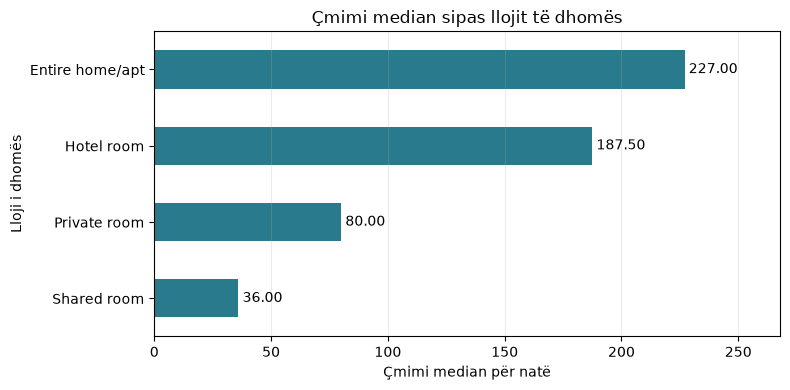

In [25]:
if "room_type" in raw.columns:
    cmimet_mediane = (agregimi_room_type
                      .dropna(subset=["cmimi_median"])
                      .set_index("room_type")["cmimi_median"]
                      .sort_values())
    ax = cmimet_mediane.plot.barh(figsize=(8, 4), color="#287a8c")
    ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
    ax.set(xlabel="Çmimi median për natë", ylabel="Lloji i dhomës",
           title="Çmimi median sipas llojit të dhomës")
    ax.grid(axis="x", alpha=0.25)
    ax.margins(x=0.18)
    ax.figure.tight_layout()
    plt.show()

### 4.3 Agregimi sipas kapacitetit

Krahasojmë numrin e listimeve dhe çmimin median sipas numrit të mysafirëve që mund të akomodohen. Mediana llogaritet vetëm për listimet që kanë çmim; numri i listimeve përfshin edhe ato pa çmim. Grafiku paraqet kapacitetet më të shpeshta, që të mbetet i lexueshëm.


,numri_listimeve,cmimi_median
accommodates,,
1,9892,65.000
2,35707,118.000
3,6900,161.635
4,19177,223.635
5,5247,248.900
6,8330,305.000
7,1736,308.690
8,2729,368.000
9,548,332.000


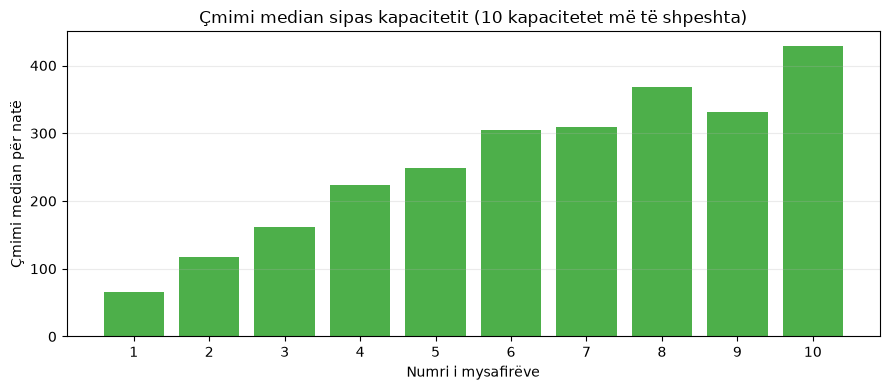

In [26]:
agregimi_kapacitet = raw.groupby("accommodates").agg(
    numri_listimeve=("id", "count"),
    cmimi_median=("price_numeric", "median")
).sort_index()

display(agregimi_kapacitet)

kapacitetet = agregimi_kapacitet.nlargest(10, "numri_listimeve").sort_index()
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(kapacitetet.index.astype(str), kapacitetet["cmimi_median"], color="#4daf4a")
ax.set(xlabel="Numri i mysafirëve", ylabel="Çmimi median për natë",
       title="Çmimi median sipas kapacitetit (10 kapacitetet më të shpeshta)")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()


### 4.4 Agregimi sipas pronarit

In [27]:
if "host_id" in raw.columns:
    agregimi_host = raw.groupby("host_id").agg(
        numri_listimeve=("id", "count"),
        cmimi_median=("price_numeric", "median")
    ).reset_index()

    agregimi_host = agregimi_host.sort_values("numri_listimeve", ascending=False)
    display(agregimi_host.head(10))

    print("Numri i pronarëve:", len(agregimi_host))
    print("Pronarë me më shumë se një listim:", (agregimi_host["numri_listimeve"] > 1).sum())

,host_id,numri_listimeve,cmimi_median
41358,446820235,501,447.200
15740,28820321,273,260.390
1123,1432477,209,215.500
38203,314162972,187,NaN
17391,33889201,180,608.665
8591,11515631,164,258.750
48258,682491797,161,175.500
43886,509948385,150,118.000
6509,7701687,149,385.000
26981,89355192,149,202.700


Numri i pronarëve: 51348
Pronarë me më shumë se një listim: 10384


## 5. Anomalitë e cilësisë dhe lidhja me pastrimin

Pas eksplorimit, kontrollojmë vlerat e pazakonta që mund të ndikojnë analizën. Një vlerë e rrallë ose ekstreme nuk është domosdoshmërisht gabim. Këtu dokumentojmë gjetjet; notebook-u 02 zbaton vendimet për pastrim.

Netët maksimale shqyrtohen për kufizim; dhomat mbi kapacitetin shënohen për kontroll; studiot me zero dhoma gjumi ruhen. Kolonat konstante dhe kopjet e çmimit shqyrtohen për zgjedhjen e vetive. Kategoritë e rralla të pronës grupohen në notebook-un 03.


### 5.1 Vlerat e pazakonta të netëve, dhomave dhe kapacitetit

In [28]:
# Vlera maksimale e netëve
if "maximum_nights" in raw.columns:
    print("Vlera më e madhe e maximum_nights:", raw["maximum_nights"].max())
    print("Rreshta me numër shumë të madh netësh:", (raw["maximum_nights"] > 100000).sum())

# Listime ku numri i dhomave të gjumit është më i madh se kapaciteti
if "bedrooms" in raw.columns and "accommodates" in raw.columns:
    print("bedrooms > accommodates:", ((raw["bedrooms"] > raw["accommodates"]) & raw["bedrooms"].notna() & raw["accommodates"].notna()).sum())
    print("bedrooms = 0:", (raw["bedrooms"] == 0).sum())

Vlera më e madhe e maximum_nights: 2147483647.0
Rreshta me numër shumë të madh netësh: 15
bedrooms > accommodates: 632
bedrooms = 0: 3264


### 5.2 Vlerat e pazakonta të pronarëve

In [29]:
if "host_listings_count" in raw.columns:
    print("Vlera maksimale e host_listings_count:", raw["host_listings_count"].max())
    print("Pronarë me më shumë se 100 listime:", (raw["host_listings_count"] > 100).sum())

if "host_id" in raw.columns:
    listime_per_host = raw.groupby("host_id").size()
    print("Numri i pronarëve:", len(listime_per_host))
    print("Pronarë me më shumë se një listim:", (listime_per_host > 1).sum())

Vlera maksimale e host_listings_count: 5777
Pronarë me më shumë se 100 listime: 4728
Numri i pronarëve: 51348
Pronarë me më shumë se një listim: 10384


### 5.3 Kolonat konstante ose të përsëritura

In [30]:
# Kolonat ku të gjitha vlerat jo-boshe janë të njëjta
kolona_konstante = []
for col in raw.columns:
    if raw[col].nunique(dropna=True) <= 1:
        kolona_konstante.append(col)

print("Kolonat konstante ose pa vlera të ndryshme:")
print(kolona_konstante)

# Kontrollojmë nëse kolonat price_quote_* janë të njëjta me price
if "price" in raw.columns:
    for col in raw.columns:
        if col.startswith("price_quote_"):
            njesoj = raw[col].equals(raw["price"])
            print(col, "është identike me price:", njesoj)

Kolonat konstante ose pa vlera të ndryshme:
['scrape_id', 'source', 'neighborhood_overview', 'host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url', 'host_neighbourhood', 'host_total_listings_count', 'host_verifications', 'neighbourhood', 'neighbourhood_group_cleansed', 'bathrooms', 'calendar_updated', 'license', 'instant_bookable']
price_quote_checkin_date është identike me price: False
price_quote_checkout_date është identike me price: False
price_quote_total_price është identike me price: False
price_quote_price_per_night është identike me price: False
price_quote_raw është identike me price: False


### 5.4 Kategoritë e rralla të `property_type`

In [31]:
if "property_type" in raw.columns:
    print("Numri i llojeve të property_type:", raw["property_type"].nunique())
    print("Llojet me vetëm një listim:")
    display(raw["property_type"].value_counts().loc[lambda x: x == 1].to_frame("Numri i listimeve"))

Numri i llojeve të property_type: 89
Llojet me vetëm një listim:


,Numri i listimeve
property_type,
Shared room in loft,1
Private room in chalet,1
Private room in floor,1
Earthen home,1
Tent,1
Dome,1
Private room in treehouse,1
Minsu,1
Island,1


# Pjesa I · 2/4: Pastrimi final i të dhënave

**Pyetja e analizës:** si ndryshon çmimi për natë i listimeve Airbnb në Londër? Për ta analizuar, na duhet një tabelë me çmim të vlefshëm, pa dublikatë, me mungesa të shpjeguara dhe pa çmime që janë gabime të dukshme.

Ky notebook e ndërton atë tabelë nga skedari origjinal i Inside Airbnb, i cili nuk ndryshohet kurrë. Çdo hap tregon çfarë bëhet, pse bëhet dhe sa rreshta ose vlera preken.

| Hapi | Çfarë bëhet |
|---|---|
| 1. Pastrimi bazë | heqim kolonat krejt bosh, kolonat konstante (`scrape_id`) dhe ID-të e dyfishta; çmimin, datat dhe fushat `t/f` i kthejmë në tipet e duhura |
| 1.1 Integrimi: komentet | bashkojmë `reviews.csv` me `listing_id = id`: numri i komenteve dhe data e parë dhe e fundit për çdo listim; mungesat e reja që krijon bashkimi trajtohen menjëherë. Rezultati përputhet 100% me kolonat ekzistuese, ndaj shërben si kontroll |
| 1.2 Integrimi: kalendari | bashkojmë `calendar.csv` me `listing_id = id`: ditët e lira dhe disponueshmëria e fundjavës sipas ditës. Çdo listim ka kalendar, ndaj nuk krijohen mungesa; informacioni i ri është modest |
| 2. Mungesat | heqim listimet pa çmim (me arsyetim); mbajmë dhe shënojmë listimet me çmim nga mbledhja e mëparshme (`is_previous_scrape`); plotësojmë `bathrooms`, `bedrooms`, `beds` dhe fushat e tjera ku ka kuptim; të tjerat i lëmë bosh me qëllim |
| 3. Vlerat ekstreme dhe anomalitë | heqim çmimet e pabesueshme (mbi percentilin 99.9 të llojit të dhomës; asimetria e çmimit bie nga 62.7 në 8.3), shënojmë ato mbi percentilin 99, kufizojmë `maximum_nights` në 1,125, shënojmë listimet me më shumë `bedrooms` se `accommodates` dhe dokumentojmë `price_quote_*` si kolona të nxjerra nga çmimi |
| 4. Vetitë e reja | `has_reviews`, `is_superhost`, `price_band` dhe `amenity_count` |
| 5. Zgjedhja e vetive | 18 kolona të lidhura me pyetjen e analizës (tabelë analize; zgjedhja përfundimtare e vetive bëhet te notebook-u 04) |
| 6. Agregimi | çmimi median sipas llojit të dhomës dhe lagjes (standardizimi dhe kodimi 0/1 bëhen te notebook-et 03 dhe 04) |
| 7. Kontrolli dhe ruajtja | para/pas, çfarë ndodhi me çdo rresht dhe çdo mungesë, kontrolle që ndalojnë ekzekutimin nëse ka mbetur problem |

**Dalja** (dy skedarë në `dataset/`):
- `listings_clean_full.csv` · tabela e plotë e pastruar, me të gjitha kolonat;
- `listings_preprocessed.csv` · tabela me 18 kolona për analizën e çmimit.

**Si ekzekutohet:** ekzekutoni së pari notebook-un 01 për të parë problemet fillestare, pastaj këtë nga rrënja e projektit ose nga `notebooks/`. Ai gjen vetë `dataset/listings.csv.gz`, `dataset/reviews.csv.gz` dhe `dataset/calendar.csv.gz` (i njëjti snapshot, 2026-09-17); për skedarë të tjerë vendosni `PVDH_DATASET_PATH`, `PVDH_REVIEWS_PATH` dhe `PVDH_CALENDAR_PATH`. Ekzekutimi i plotë zgjat nga disa dhjetëra sekonda deri në pak minuta, sipas kompjuterit; pjesa më e madhe është leximi i kalendarit.

## 0. Burimi i të dhënave

Të dhënat vijnë nga **Inside Airbnb**, listimet e Londrës (faqja: `insideairbnb.com/get-the-data`). Një rresht i `listings` përfaqëson një listim; `id` është çelësi me të cilin bashkohen skedarët e tjerë.

| Skedari | Përmbajtja | Madhësia |
|---|---|---|
| `listings.csv.gz` | një rresht për listim | 91,954 rreshta × 90 kolona |
| `reviews.csv.gz` | një rresht për koment | 2,323,969 rreshta |
| `calendar.csv.gz` | një rresht për listim dhe ditë | 33,563,890 rreshta |

Të tre janë versioni i datës **2026-09-17** (kolona `last_scraped` ka data nga 2026-09-18 deri më 2026-09-23). Lidhjet e shkarkimit:

```
https://data.insideairbnb.com/united-kingdom/england/london/2026-09-17/data/listings.csv.gz
https://data.insideairbnb.com/united-kingdom/england/london/2026-09-17/data/reviews.csv.gz
https://data.insideairbnb.com/united-kingdom/england/london/2026-09-17/data/calendar.csv.gz
```

Skedarët ruhen te `dataset/` dhe nuk përfshihen në Git (janë shumë të mëdhenj); README tregon si shkarkohen. Skedari origjinal nuk ndryshohet kurrë. Nga komentet lexojmë vetëm `listing_id` dhe `date`: emrat dhe teksti janë të dhëna personale që analiza nuk i përdor. Kushtet e përdorimit të të dhënave gjenden te faqja e burimit.

In [32]:
import json
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(os.environ.get("PVDH_PROJECT_ROOT", Path.cwd()))
if not (ROOT / "dataset" / "listings.csv.gz").is_file() and (ROOT.parent / "dataset" / "listings.csv.gz").is_file():
    ROOT = ROOT.parent
DATA_PATH = Path(os.environ.get("PVDH_DATASET_PATH", ROOT / "dataset" / "listings.csv.gz"))
assert DATA_PATH.is_file(), f"Mungon dataset-i: {DATA_PATH}"
raw = pd.read_csv(DATA_PATH, low_memory=False, dtype={"host_profile_id": "string"})
df = raw.copy()
log = []
removed = {}  # rreshtat e larguara dhe arsyeja
def record(step):
    log.append({"hapi": step, "rreshta": len(df), "kolona": df.shape[1], "qeliza boshe": int(df.isna().sum().sum())})
record("Fillimi")
print(f"Burimi: {DATA_PATH.name} | Fillimi: {len(df):,} rreshta × {df.shape[1]} kolona")

Burimi: listings.csv.gz | Fillimi: 91,954 rreshta × 90 kolona


## 1. Pastrimi bazë dhe tipet

Heqim kolonat 100% boshe dhe ID-të e përsëritura, por ruajmë `bathrooms`: megjithëse është bosh në këtë version, mund ta rindërtojmë nga `bathrooms_text`. Heqim edhe kolonat konstante (një vlerë e vetme, pa asnjë mungesë), si `scrape_id`, sepse nuk japin asnjë informacion; `source` mbetet, sepse ka dy gjendje (bosh dhe `previous scrape`). Kthejmë `price` në numër duke larguar formatimin (`$`, presje). Datat ruhen si `datetime`, ndërsa `t/f` bëhet `True/False` pa e ngatërruar mungesën me `False`.

In [33]:
empty_columns = [col for col in df.columns[df.isna().all()] if col != "bathrooms"]
df = df.drop(columns=empty_columns)
# Kolona konstante: një vlerë e vetme dhe asnjë mungesë; nuk japin asnjë informacion (p.sh. scrape_id).
constant_columns = {col: df[col].iloc[0] for col in df.columns if df[col].notna().all() and df[col].nunique() == 1}
df = df.drop(columns=list(constant_columns))
removed["ID e dyfishuar"] = int(df["id"].duplicated().sum())
df = df.drop_duplicates(subset="id", keep="first").copy()
df["price"] = pd.to_numeric(df["price"].astype("string").str.replace(r"[$,]", "", regex=True), errors="coerce")
for col in ["last_scraped", "calendar_last_scraped", "first_review", "last_review"]:
    if col in df:
        df[col] = pd.to_datetime(df[col], errors="coerce")
boolean_columns = ["host_is_superhost", "host_has_profile_pic", "host_identity_verified", "has_availability"]
for col in boolean_columns:
    if col in df:
        df[col] = df[col].map({"t": True, "f": False}).astype("boolean")
record("Kolona boshe, konstante, ID, tipe")
print(f"Kolona 100% boshe të hequra: {len(empty_columns)}: {', '.join(empty_columns)}")
print(f"Kolona konstante të hequra: {', '.join(f'{col} = {value}' for col, value in constant_columns.items()) or 'asnjë'}")
print(f"ID të dyfishuara të hequra: {removed['ID e dyfishuar']}")
display(df[["price", "last_scraped", "host_is_superhost"]].dtypes.to_frame("tipi i korrigjuar"))

Kolona 100% boshe të hequra: 14: neighborhood_overview, host_since, host_response_time, host_response_rate, host_acceptance_rate, host_thumbnail_url, host_neighbourhood, host_total_listings_count, host_verifications, neighbourhood, neighbourhood_group_cleansed, calendar_updated, license, instant_bookable
Kolona konstante të hequra: scrape_id = 20260917015706
ID të dyfishuara të hequra: 0


,tipi i korrigjuar
price,Float64
last_scraped,datetime64[ns]
host_is_superhost,boolean


### 1.1 Integrimi: komentet nga `reviews.csv`

Deri tani kemi përdorur vetëm `listings.csv`. Shtojmë `reviews.csv.gz` të të njëjtit snapshot të Inside Airbnb (Londër, 2026-09-17; `listings.csv.gz` lokal është identik me atë të snapshot-it) dhe e bashkojmë me listimet me `listing_id = id`.

Skedari ka një rresht për çdo koment, prandaj e përmbledhim fillimisht **në një rresht për listim** (numri i komenteve, data e parë dhe e fundit). Po ta bashkonim drejtpërdrejt, çdo listim do të shumëzohej me numrin e komenteve të tij. Lexojmë vetëm `listing_id` dhe `date`: emrat e komentuesve dhe teksti janë të dhëna personale që analiza e çmimit nuk i përdor.

Bashkimi është një *left join*, ndaj asnjë listim nuk humbet. Ai krijon mungesa të reja, që i trajtojmë menjëherë: një listim pa komente ka **0** komente (`reviews_in_file` plotësohet me 0), por nuk ka datë (`first_review_in_file` dhe `last_review_in_file` **lihen bosh me qëllim**, njësoj si `first_review` dhe `last_review`).

**Rezultati.** Skedari ka 2,323,969 komente për 71,260 listime; 20,694 listime nuk kanë asnjë koment dhe asnjë `listing_id` i komenteve nuk mbetet pa listim. Numri i komenteve dhe data e fundit përputhen me `number_of_reviews` dhe `last_review` te **100%** e listimeve: bashkimi është i saktë, por kolonat e reja janë kopje të atyre ekzistuese dhe shërbejnë vetëm si kontroll. Skedari ruhet te `dataset/reviews.csv.gz` (jo në Git); për një rrugë tjetër vendosni `PVDH_REVIEWS_PATH`.

In [34]:
REVIEWS_PATH = Path(os.environ.get("PVDH_REVIEWS_PATH", ROOT / "dataset" / "reviews.csv.gz"))
assert REVIEWS_PATH.is_file(), f"Mungon skedari i komenteve: {REVIEWS_PATH}"
# Lexojmë vetëm listing_id dhe date: emrat e komentuesve dhe teksti nuk nevojiten dhe janë të dhëna personale.
reviews = pd.read_csv(REVIEWS_PATH, usecols=["listing_id", "date"], parse_dates=["date"])
by_listing = reviews.groupby("listing_id")["date"].agg(
    reviews_in_file="size", first_review_in_file="min", last_review_in_file="max"
)
reviews_without_listing = int((~by_listing.index.isin(df["id"])).sum())

rows_before = len(df)
joined_columns = list(by_listing.columns)
for col in joined_columns:
    df[col] = df["id"].map(by_listing[col])
assert len(df) == rows_before, "Bashkimi nuk duhet të ndryshojë numrin e rreshtave"
joined_snapshot = df[joined_columns].copy()  # mungesat që krijoi bashkimi, për tabelën 7.3
no_reviews_in_file = df["reviews_in_file"].isna()
df["reviews_in_file"] = df["reviews_in_file"].fillna(0).astype("int64")
record("Integrimi: numri dhe datat e komenteve nga reviews.csv")

print(f"Komente në skedar: {len(reviews):,} për {len(by_listing):,} listime")
print(f"Listime pa asnjë koment në skedar: {int(no_reviews_in_file.sum()):,} (numri bëhet 0, datat mbeten bosh)")
print(f"listing_id në komente pa listim në dataset: {reviews_without_listing:,}")
same_count = df["reviews_in_file"].eq(df["number_of_reviews"])
same_last = df["last_review_in_file"].eq(df["last_review"]) | (df["last_review_in_file"].isna() & df["last_review"].isna())
print(f"Përputhja me kolonat ekzistuese: numri i komenteve te {same_count.mean():.1%} e listimeve, data e fundit te {same_last.mean():.1%}")
display(df.loc[~same_count, ["id", "number_of_reviews", "reviews_in_file", "last_review", "last_review_in_file"]].head())

Komente në skedar: 2,323,969 për 71,260 listime
Listime pa asnjë koment në skedar: 20,694 (numri bëhet 0, datat mbeten bosh)
listing_id në komente pa listim në dataset: 0
Përputhja me kolonat ekzistuese: numri i komenteve te 100.0% e listimeve, data e fundit te 100.0%


,id,number_of_reviews,reviews_in_file,last_review,last_review_in_file


### 1.2 Integrimi: kalendari nga `calendar.csv`

Burimi i dytë është `calendar.csv.gz` i të njëjtit snapshot: një rresht për çdo listim dhe ditë (33,563,890 rreshta), me `available` (`t`/`f`) dhe `minimum_nights` e `maximum_nights` për atë ditë; ne përdorim vetëm `available`. **Nuk ka çmim**, ndaj nuk mund të plotësojë çmimet që mungojnë; jep disponueshmërinë sipas datës, ndërsa listimet e kanë vetëm si total (`availability_365`).

Si më sipër, e përmbledhim **në një rresht për listim** me `listing_id = id`, duke e lexuar me copa prej 2 milionë rreshtash që të mos mbushet kujtesa. Krijojmë dy veti: `calendar_available_days` (sa ditë janë të lira) dhe `calendar_weekend_availability` (pjesa e netëve të së premtes dhe të së shtunës që janë të lira).

**Mungesat.** Çdo listim ka kalendar, ndaj bashkimi nuk krijon asnjë vlerë që mungon. Një listim pa kalendar nuk do të plotësohej me 0 (disponueshmëria do të ishte e panjohur, jo zero), prandaj qeliza ndalon nëse ndodh kjo.

**Rezultati.** Të 91,954 listimet kanë kalendar. `calendar_available_days` përputhet me `availability_365` te 99.6% e listimeve, pra është kryesisht kontroll. Vetëm `calendar_weekend_availability` shton diçka të re, por pak: ajo ndryshon nga disponueshmëria mesatare e vitit me mbi 5 pikë përqindjeje te 6.3% e listimeve. Te reduktimi i dimensionit (notebook-u 04) kolonat e integrimit, përveç kësaj të fundit, duhen hequr si të përsëritura.

In [35]:
CALENDAR_PATH = Path(os.environ.get("PVDH_CALENDAR_PATH", ROOT / "dataset" / "calendar.csv.gz"))
assert CALENDAR_PATH.is_file(), f"Mungon skedari i kalendarit: {CALENDAR_PATH}"

def summarise_calendar(path, chunksize=2_000_000):
    # Skedari ka rreth 33 milionë rreshta (një për listim dhe ditë): e lexojmë me copa dhe mbledhim shumat për listim.
    totals = []
    for chunk in pd.read_csv(path, usecols=["listing_id", "date", "available"], chunksize=chunksize):
        is_weekend = pd.to_datetime(chunk["date"]).dt.dayofweek.isin([4, 5])  # netët e së premtes dhe të së shtunës
        is_available = chunk["available"].eq("t")
        flags = pd.DataFrame({
            "listing_id": chunk["listing_id"],
            "days": 1,
            "available_days": is_available,
            "weekend_days": is_weekend,
            "weekend_available_days": is_available & is_weekend,
        })
        totals.append(flags.groupby("listing_id").sum())
    totals = pd.concat(totals).groupby(level=0).sum()
    return pd.DataFrame({
        "calendar_days": totals["days"],
        "calendar_available_days": totals["available_days"],
        "calendar_weekend_availability": totals["weekend_available_days"] / totals["weekend_days"],
    })

calendar_summary = summarise_calendar(CALENDAR_PATH)
calendar_columns = ["calendar_available_days", "calendar_weekend_availability"]
calendar_without_listing = int((~calendar_summary.index.isin(df["id"])).sum())

rows_before = len(df)
for col in calendar_columns:
    df[col] = df["id"].map(calendar_summary[col])
assert len(df) == rows_before, "Bashkimi nuk duhet të ndryshojë numrin e rreshtave"
listings_without_calendar = int(df[calendar_columns].isna().any(axis=1).sum())
# Një listim pa kalendar do të linte një boshllëk të heshtur (jo 0: disponueshmëria do të ishte e panjohur); ndalojmë.
assert listings_without_calendar == 0, f"Listime pa kalendar: {listings_without_calendar:,}"
record("Integrimi: disponueshmëria sipas ditës nga calendar.csv")

print(f"Kalendar: {int(calendar_summary['calendar_days'].sum()):,} rreshta për {len(calendar_summary):,} listime")
print(f"listing_id në kalendar pa listim: {calendar_without_listing:,}; listime pa kalendar: {listings_without_calendar:,}; mungesa të reja: {int(df[calendar_columns].isna().sum().sum())}")
same_days = df["calendar_available_days"].eq(df["availability_365"])
print(f"calendar_available_days = availability_365 te {same_days.mean():.1%} e listimeve")
overall_availability = (calendar_summary["calendar_available_days"] / calendar_summary["calendar_days"]).reindex(df["id"]).to_numpy()
weekend_gap = df["calendar_weekend_availability"] - overall_availability
print(f"Disponueshmëria e fundjavës dallon nga mesatarja e vitit me mbi 5 pikë përqindjeje te {(weekend_gap.abs() > 0.05).mean():.1%} e listimeve")

Kalendar: 33,563,890 rreshta për 91,954 listime
listing_id në kalendar pa listim: 0; listime pa kalendar: 0; mungesa të reja: 0
calendar_available_days = availability_365 te 99.6% e listimeve
Disponueshmëria e fundjavës dallon nga mesatarja e vitit me mbi 5 pikë përqindjeje te 6.3% e listimeve


## 2. Trajtimi i mungesave

`price` është variabla që duam të analizojmë. Nuk e plotësojmë me mesatare, sepse kjo do të krijonte çmime të sajuara; heqim rreshtat pa çmim. Para se t'i heqim, shohim cilët janë (tabela e parë më poshtë):

- **32,049 listime nuk kanë çmim.** 92.7% e tyre vijnë nga një mbledhje e mëparshme (`source = 'previous scrape'`), kundrejt 4.3% te listimet me çmim.
- **87.3% e tyre nuk kanë asnjë ditë të lirë** në vitin e ardhshëm (`availability_365 = 0`), kundrejt vetëm 0.5% te listimet me çmim.

Pra janë kryesisht listime jashtë shitjes dhe nga një mbledhje e vjetër, jo listime të zakonshme që thjesht kanë harruar çmimin. Kufizim: analiza e çmimit përfaqëson vetëm listimet që kanë çmim të njohur.

**Çfarë bëjmë me 2,587 listimet që kanë çmim por `source = 'previous scrape'`?** Tabela e dytë i krahason me të tjerat: çmimi median është 149 kundrejt 176, ndërsa ditët e lira mediane janë 33 kundrejt 260. Çmimet nuk duken të gabuara, por këto listime janë shumë më pak të disponueshme. Vendimi: **i mbajmë dhe i shënojmë** te `is_previous_scrape`, që analiza ta përjashtojë si kontroll nëse dëshiron. Shtatë prej tyre hiqen më vonë si çmime ekstreme (hapi 3), ndaj te tabela finale mbeten 2,580.

Pastaj plotësojmë këto mungesa:
- `bathrooms` rindërtohet nga `bathrooms_text` (p.sh. *1.5 baths* → 1.5, *Half-bath* → 0.5, *No bathroom* → 0).
- `has_availability` merret nga `availability_365`: `True` kur listimi ka ditë të lira në vitin e ardhshëm.
- Për `bathrooms`, `bedrooms` dhe `beds`, mungesat e mbetura plotësohen me medianën e listimeve me të njëjtin `accommodates`, pastaj me medianën e përgjithshme. Kjo është supozim praktik dhe duhet përmendur si kufizim.
- Mungesat në rezultatet e komenteve ruhen: listimi pa komente nuk ka vlerësim. `reviews_per_month` bëhet 0 vetëm kur `number_of_reviews == 0`.

In [36]:
status = df["price"].isna().map({True: "pa çmim", False: "me çmim"}).rename(None)
display(pd.DataFrame({
    "listime": status.value_counts(),
    "% pa ditë të lira (availability_365 = 0)": df["availability_365"].eq(0).groupby(status).mean().mul(100),
    "% me burim 'previous scrape'": df["source"].eq("previous scrape").groupby(status).mean().mul(100),
}).round(1))

priced = df.dropna(subset=["price"])
by_source = priced["source"].eq("previous scrape").map({True: "previous scrape", False: "burime të tjera"}).rename(None)
display(priced.groupby(by_source).agg(
    listime=("id", "size"), cmimi_median=("price", "median"), dite_te_lira_mediane=("availability_365", "median")
).round(1))

removed["pa çmim"] = int(df["price"].isna().sum())
df = df.dropna(subset=["price"]).copy()
removed["çmim <= 0"] = int(df["price"].le(0).sum())
df = df[df["price"].gt(0)].copy()
# source është bosh për mbledhjet e zakonshme, ndaj shenja është eksplicite: True vetëm për 'previous scrape'.
df["is_previous_scrape"] = df["source"].eq("previous scrape")
record("Heqja e çmimit të munguar/jo pozitiv")
print(f"Pa çmim: {removed['pa çmim']:,}; çmim <= 0: {removed['çmim <= 0']:,}")
print(f"Listime me çmim dhe source = 'previous scrape': {int(df['is_previous_scrape'].sum()):,} (mbahen, shënuar te is_previous_scrape)")

,listime,% pa ditë të lira (availability_365 = 0),% me burim 'previous scrape'
me çmim,59905,0.5,4.3
pa çmim,32049,87.3,92.7


,listime,cmimi_median,dite_te_lira_mediane
burime të tjera,57318,176.0,260.0
previous scrape,2587,149.0,33.0


Pa çmim: 32,049; çmim <= 0: 0
Listime me çmim dhe source = 'previous scrape': 2,587 (mbahen, shënuar te is_previous_scrape)


In [37]:
def bathrooms_from_text(bathrooms_text):
    # Numri te teksti si '1.5 shared baths'; 'Half-bath' është 0.5 dhe 'No bathroom' është 0.
    text = bathrooms_text.astype("string")
    numbers = text.str.extract(r"(\d+(?:\.\d+)?)")[0].astype(float)
    half_bath = text.str.contains("half", case=False, na=False)
    no_bath = text.str.contains(r"^no bath", case=False, na=False)
    return numbers.mask(numbers.isna() & half_bath, 0.5).mask(numbers.isna() & no_bath, 0.0)

missing_bathrooms = int(df["bathrooms"].isna().sum())
df["bathrooms"] = df["bathrooms"].fillna(bathrooms_from_text(df["bathrooms_text"]))
print(f"bathrooms të rindërtuara nga bathrooms_text: {missing_bathrooms - int(df['bathrooms'].isna().sum()):,}")

missing_availability = int(df["has_availability"].isna().sum())
df["has_availability"] = df["has_availability"].fillna(df["availability_365"].gt(0))
print(f"has_availability të plotësuara nga availability_365: {missing_availability}")

imputations = {}
for col in ["bathrooms", "bedrooms", "beds"]:
    before = int(df[col].isna().sum())
    group_median = df.groupby("accommodates")[col].transform("median")
    df[col] = df[col].fillna(group_median).fillna(df[col].median())
    imputations[col] = before - int(df[col].isna().sum())
no_reviews = df["number_of_reviews"].eq(0)
df.loc[no_reviews & df["reviews_per_month"].isna(), "reviews_per_month"] = 0

# Numrat e dhomave dhe të viteve ruhen si numra të plotë (1, jo 1.0).
integer_columns = [col for col in ["bedrooms", "beds", "host_listings_count", "hosts_time_as_user_years",
                                   "hosts_time_as_user_months", "hosts_time_as_host_years",
                                   "hosts_time_as_host_months"] if col in df]
df[integer_columns] = df[integer_columns].round().astype("Int64")
record("Plotësimi i zgjedhur i mungesave")
display(pd.Series(imputations, name="vlera të plotësuara me medianë").to_frame())

bathrooms të rindërtuara nga bathrooms_text: 59,813
has_availability të plotësuara nga availability_365: 3


,vlera të plotësuara me medianë
bathrooms,92
bedrooms,24
beds,1502


## 3. Vlerat ekstreme dhe anomalitë

Një çmim i lartë mund të jetë gabim ose listim luksoz, prandaj e trajtojmë në dy hapa.

1. **Çmimet e pabesueshme hiqen.** Një çmim normal për një shtëpi të tërë mund të jetë gabim për një dhomë të vetme, prandaj kufiri është percentili 99.9 **i secilit lloj dhome**. Shembuj që hiqen: një dhomë private për 1 mysafir me çmim 75,000. Çmime të tilla shtrembërojnë mesataret dhe shkallëzimin. Kufizim: në grupet me më pak se 1,000 listime (`Shared room`, `Hotel room`) percentili 99.9 bie mes dy çmimeve më të larta, prandaj hiqet çmimi më i lartë i grupit.
2. **Çmimet e larta që mbeten vetëm shënohen.** Mbi percentilin 99 (të llogaritur pas hapit të parë) vendosim `price_above_p99`, por **nuk i fshijmë**: mund të jenë listime të vërteta luksoze. Histogrami përdor vetëm vlerat deri në këtë kufi që pjesa kryesore e të dhënave të lexohet qartë; tabela ruan të gjitha çmimet që mbeten.

**Politika e çmimit, me numra.** Para heqjes çmimi ka asimetri (*skewness*) 62.7: 27 listime kanë çmim 10,000 ose më shumë dhe maksimumi është 75,000. Pas heqjes së 59 çmimeve ekstreme nuk mbetet asnjë listim mbi 10,000 dhe asimetria bie në 8.3; pas `log1p` do të ishte 0.31. Logaritmin e lëmë për notebook-un 04 (transformimi), prandaj këtu `price` mbetet në njësinë origjinale. Kufiri 99.9 është statistikor, jo provë se çmimi është gabim: disa nga 40 shtëpitë e plota të hequra (p.sh. 23,520 për 16 mysafirë) mund të jenë të vërteta. E pranojmë këtë kufizim, sepse ato do të shtrembëronin mesataret dhe shkallëzimin.

In [38]:
PRICE_DROP_QUANTILE = 0.999
highest_price = df["price"].max()
skew_before = df["price"].skew()
count_10k_before = int(df["price"].ge(10_000).sum())
drop_limits = df.groupby("room_type")["price"].quantile(PRICE_DROP_QUANTILE)
is_extreme = df["price"].gt(df["room_type"].map(drop_limits))
extreme_rows = df.loc[is_extreme, ["id", "room_type", "accommodates", "price"]].sort_values("price", ascending=False)
removed["çmim ekstrem"] = len(extreme_rows)
df = df[~is_extreme].copy()
record("Heqja e çmimeve ekstreme (P99.9 sipas llojit të dhomës)")
print(f"Çmimi më i lartë para heqjes: {highest_price:,.0f}; rreshta të hequr: {len(extreme_rows)}")
print(f"Listime me çmim >= 10,000: {count_10k_before} para heqjes, {int(df['price'].ge(10_000).sum())} pas saj")
print(f"Asimetria e çmimit: {skew_before:.1f} para heqjes, {df['price'].skew():.1f} pas saj, {np.log1p(df['price'].astype(float)).skew():.2f} pas log1p")
display(pd.DataFrame({
    "kufiri (P99.9)": drop_limits.round(0),
    "rreshta të hequr": extreme_rows["room_type"].value_counts().reindex(drop_limits.index, fill_value=0),
    "çmimi më i lartë i mbetur": df.groupby("room_type")["price"].max(),
}))
display(extreme_rows.head(10))

Çmimi më i lartë para heqjes: 75,000; rreshta të hequr: 59
Listime me çmim >= 10,000: 27 para heqjes, 0 pas saj
Asimetria e çmimit: 62.7 para heqjes, 8.3 pas saj, 0.31 pas log1p


,kufiri (P99.9),rreshta të hequr,çmimi më i lartë i mbetur
room_type,,,
Entire home/apt,6798.0,40,6798.4
Hotel room,1440.0,0,1440.0
Private room,5000.0,18,5000.0
Shared room,2083.0,1,622.5


,id,room_type,accommodates,price
9263,13254774,Private room,1,75000.0
59223,1289811437722717777,Private room,3,59214.0
53774,1203041287118705621,Private room,3,28000.0
53920,1183168933886992107,Private room,3,23686.0
54210,1207889725595849665,Entire home/apt,16,23520.0
61863,1342870516779702858,Entire home/apt,2,16318.4
55464,1196233560198207804,Entire home/apt,16,14744.0
42564,943540074261545116,Entire home/apt,2,12000.0
60961,1334074652906908090,Entire home/apt,16,10708.0
34324,644043613421252064,Entire home/apt,10,10679.0


P99: 1203.38; listime mbi kufi: 599


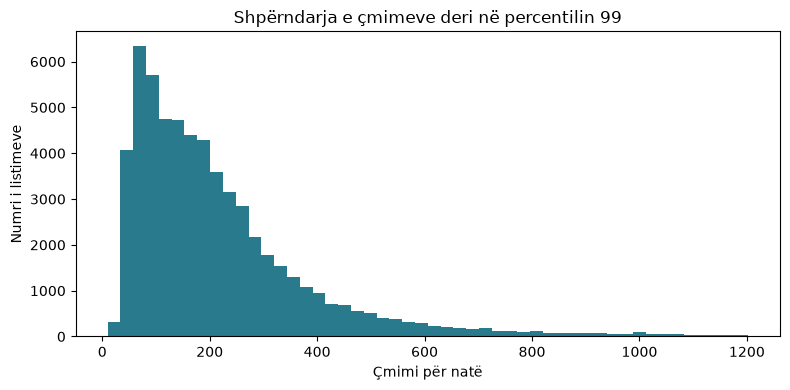

In [39]:
price_p99 = df["price"].quantile(0.99)
df["price_above_p99"] = df["price"].gt(price_p99)
print(f"P99: {price_p99:.2f}; listime mbi kufi: {int(df['price_above_p99'].sum()):,}")
ax = df.loc[~df["price_above_p99"], "price"].plot.hist(bins=50, figsize=(8, 4), color="#287a8c")
ax.set(xlabel="Çmimi për natë", ylabel="Numri i listimeve", title="Shpërndarja e çmimeve deri në percentilin 99")
plt.tight_layout()
plt.show()
record("Shënimi i çmimeve mbi P99")

### Anomali në kolona të tjera

Këto kolona kanë vlera të pazakonta që nuk janë gabime çmimi, prandaj këtu **nuk fshijmë rreshta**. Është e njëjta politikë si për çmimin: heqim vetëm atë që është gabim i dukshëm dhe shënojmë atë që mund të jetë e vërtetë.

- **`maximum_nights`** (dhe kolonat e tjera të netëve maksimale) ka vlera si 2,147,483,647, kufiri i një numri të plotë 32-bit. Ajo nuk është një numër i vërtetë netësh, por një shenjë "pa kufi". Kufizojmë vlerat në 1,125, që është vlera maksimale e zakonshme dhe percentili 99 i dataset-it. Listimi mbetet, hiqet vetëm vlera absurde.
- **`bedrooms` > `accommodates`** (p.sh. 2 dhoma gjumi për 1 mysafir) është e pazakontë, por jo e pamundur. Tabela më poshtë tregon se pothuajse të gjitha janë dhoma private, ndaj ka gjasa që hosti të ketë shënuar dhomat e gjithë shtëpisë. Vlerën nuk e ndryshojmë; e shënojmë te `bedrooms_above_accommodates`, që analiza ta përjashtojë ose ta shqyrtojë.
- **`bedrooms` = 0** nuk është gabim: shumica janë shtëpi të plota, pra studio. Nuk ndryshohet asgjë.
- **`host_listings_count`** arrin 5,777, ndërsa `calculated_host_listings_count` (listimet e host-it në këtë dataset) arrin 501. Vlera e raportuar nga Airbnb nuk është e qëndrueshme me dataset-in, por nuk është gabim çmimi: rreshtat mbeten dhe kolona nuk përdoret për analizë. Notebook-u 03 përdor `calculated_host_listings_count`.
- **`price_quote_*`** nuk janë veti të pavarura, por të nxjerra nga çmimi: `price_quote_price_per_night` është kopje e saktë e `price` (shih rezultatin më poshtë), `price_quote_total_price` është çmimi total i një qëndrimi shembull prej një ose më shumë netësh, dhe `price_quote_raw` e përmban çmimin si JSON. I mbajmë te tabela e plotë, por nuk futen te 18 kolonat e analizës, dhe duhen përjashtuar te zgjedhja e vetive (notebook-u 04), përndryshe një model do ta shihte vetë çmimin që duhet të parashikojë.
- **`scrape_id`** nuk është anomali, por konstante: ka të njëjtën vlerë në çdo rresht dhe hiqet te hapi 1.

In [40]:
MAX_NIGHTS_CAP = 1125
night_columns = [col for col in ["maximum_nights", "minimum_maximum_nights", "maximum_maximum_nights", "maximum_nights_avg_ntm"] if col in df]
largest_nights = df[night_columns].max().max()
capped = (df[night_columns] > MAX_NIGHTS_CAP).sum()
df[night_columns] = df[night_columns].clip(upper=MAX_NIGHTS_CAP)
display(capped.to_frame(f"vlera mbi {MAX_NIGHTS_CAP:,} të kufizuara"))
print(f"Vlera më e madhe e netëve maksimale: {largest_nights:,.0f} para kufizimit, {df[night_columns].max().max():,.0f} pas tij")

df["bedrooms_above_accommodates"] = (df["bedrooms"] > df["accommodates"]).astype(bool)
flagged = df[df["bedrooms_above_accommodates"]]
print(f"bedrooms > accommodates: {len(flagged):,} listime ({len(flagged) / len(df):.1%}), të shënuara te bedrooms_above_accommodates")
display(flagged["room_type"].value_counts().to_frame("listime të shënuara"))

studios = df["bedrooms"].eq(0)
print(f"bedrooms = 0: {int(studios.sum()):,} listime, nga të cilat {int((studios & df['room_type'].eq('Entire home/apt')).sum()):,} shtëpi të plota (studio); nuk ndryshohen")
print(f"host_listings_count: maksimumi {int(df['host_listings_count'].max()):,}; calculated_host_listings_count: maksimumi {int(df['calculated_host_listings_count'].max()):,}; nuk ndryshohen")

quote_per_night = pd.to_numeric(df["price_quote_price_per_night"].astype("string").str.replace(r"[$,]", "", regex=True), errors="coerce")
quote_known = quote_per_night.notna()
print(f"price_quote_price_per_night = price te {quote_per_night[quote_known].eq(df.loc[quote_known, 'price']).mean():.1%} e {int(quote_known.sum()):,} vlerave jo-boshe; kolonat price_quote_* mbahen, por duhen përjashtuar nga vetitë e modelit")
record("Anomali: maximum_nights i kufizuar, bedrooms > accommodates i shënuar")

,"vlera mbi 1,125 të kufizuara"
maximum_nights,23
minimum_maximum_nights,16
maximum_maximum_nights,23
maximum_nights_avg_ntm,22


Vlera më e madhe e netëve maksimale: 2,147,483,647 para kufizimit, 1,125 pas tij
bedrooms > accommodates: 375 listime (0.6%), të shënuara te bedrooms_above_accommodates


,listime të shënuara
room_type,
Private room,348
Entire home/apt,25
Hotel room,1
Shared room,1


bedrooms = 0: 2,121 listime, nga të cilat 1,728 shtëpi të plota (studio); nuk ndryshohen
host_listings_count: maksimumi 5,777; calculated_host_listings_count: maksimumi 501; nuk ndryshohen
price_quote_price_per_night = price te 100.0% e 59,702 vlerave jo-boshe; kolonat price_quote_* mbahen, por duhen përjashtuar nga vetitë e modelit


## 4. Krijimi i vetive, binarizimi dhe diskretizimi

`has_reviews` dhe `is_superhost` janë veti binare. `price_band` e ndan çmimin në tri grupe sipas tercileve të këtij dataset-i. Nëse çmimi përdoret si variabël që parashikohet, **mos përdorni `price_band` si hyrje të modelit**: ajo është krijuar nga vetë çmimi. `amenity_count` numëron lehtësitë e listuara te `amenities`; ato lexohen si listë JSON (`json.loads`), jo duke numëruar thonjëzat, sepse emri i një lehtësie mund të përmbajë vetë thonjëza.

In [41]:
df["has_reviews"] = df["number_of_reviews"].gt(0)
df["is_superhost"] = df["host_is_superhost"].astype("boolean")
df["price_band"] = pd.qcut(df["price"], q=3, labels=["i ulët", "mesatar", "i lartë"], duplicates="drop")
df["amenity_count"] = df["amenities"].fillna("[]").map(lambda text: len(json.loads(text)))
record("Vetitë e reja dhe kategoritë")
display(df[["price", "price_band", "has_reviews", "is_superhost", "amenity_count"]].head())

,price,price_band,has_reviews,is_superhost,amenity_count
0,267.5,i lartë,True,False,43
1,127.0,mesatar,True,True,44
2,137.5,mesatar,True,False,25
3,228.0,mesatar,True,False,68
5,290.0,i lartë,True,False,47


## 5. Zgjedhja e vetive dhe reduktimi i dimensionit

Për analizën e çmimit ruajmë një nënbashkësi të kuptueshme kolonash. ID-të, URL-të dhe teksti i gjatë nuk nevojiten si veti numerike në këtë fazë. `id` ruhet vetëm për gjurmim. Numri i kolonave bie edhe nga heqja e kolonave krejt bosh. PCA nuk përdoret këtu, sepse do të vështirësonte interpretimin e lagjes, llojit të dhomës dhe kapacitetit.

Këto 18 kolona janë një tabelë analize, jo bashkësia përfundimtare e vetive të një modeli: zgjedhja e justifikuar me numra (korrelacione, variancë) bëhet te notebook-u 04.

In [42]:
selected = ["id", "neighbourhood_cleansed", "room_type", "property_type", "accommodates", "bathrooms", "bedrooms", "beds", "price", "price_above_p99", "availability_365", "number_of_reviews", "reviews_per_month", "review_scores_rating", "has_reviews", "is_superhost", "amenity_count", "price_band"]
analysis = df[selected].copy()
print(f"Kolonat: {raw.shape[1]} fillestare → {df.shape[1]} pas pastrimit/krijimit → {analysis.shape[1]} për analizë")
display(analysis.head())

Kolonat: 90 fillestare → 87 pas pastrimit/krijimit → 18 për analizë


,id,neighbourhood_cleansed,room_type,property_type,accommodates,bathrooms,bedrooms,beds,price,price_above_p99,availability_365,number_of_reviews,reviews_per_month,review_scores_rating,has_reviews,is_superhost,amenity_count,price_band
0,11551,Lambeth,Entire home/apt,Entire rental unit,5,1.0,1,3,267.5,False,349,197,0.98,4.55,True,False,43,i lartë
1,13913,Islington,Private room,Private room in rental unit,1,1.0,1,1,127.0,False,350,57,0.29,4.86,True,True,44,mesatar
2,15400,Kensington and Chelsea,Entire home/apt,Entire rental unit,2,1.0,1,1,137.5,False,159,98,0.48,4.81,True,False,25,mesatar
3,24328,Wandsworth,Entire home/apt,Entire townhouse,2,1.5,1,1,228.0,False,272,97,0.50,4.90,True,False,68,mesatar
5,36299,Richmond upon Thames,Entire home/apt,Entire townhouse,5,1.5,3,3,290.0,False,350,117,0.60,4.80,True,False,47,i lartë


## 6. Agregimi

Për raportimin deskriptiv llogarisim medianën e çmimit sipas llojit të dhomës dhe lagjes. Standardizimi, kodimi 0/1 dhe transformimet e tjera (p.sh. logaritmi i çmimit) nuk bëhen këtu: janë pjesë e notebook-eve 03 dhe 04, ku kanë një vend të vetëm.

,count,median
room_type,,
Shared room,164,35.71
Private room,19067,80.0
Hotel room,134,187.5
Entire home/apt,40481,226.67


,count,median
neighbourhood_cleansed,,
Westminster,7942,281.55
Kensington and Chelsea,4648,272.5
Camden,4291,207.5
Tower Hamlets,3875,161.5
Southwark,3029,157.67
Lambeth,2829,153.0
Hackney,2826,164.38
Wandsworth,2691,185.09
Hammersmith and Fulham,2680,184.0


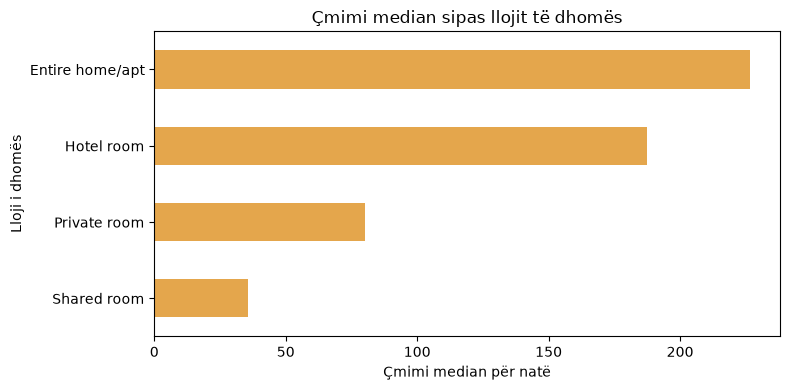

In [43]:
by_room = analysis.groupby("room_type")["price"].agg(["count", "median"]).sort_values("median")
by_area = analysis.groupby("neighbourhood_cleansed")["price"].agg(["count", "median"]).sort_values("count", ascending=False)
display(by_room.round(2))
display(by_area.head(10).round(2))
ax = by_room["median"].plot.barh(figsize=(8, 4), color="#e4a64c")
ax.set(xlabel="Çmimi median për natë", ylabel="Lloji i dhomës", title="Çmimi median sipas llojit të dhomës")
plt.tight_layout()
plt.show()

## 7. Kontrolli para/pas dhe ruajtja

Raporti tregon çfarë ndryshoi në secilin hap, çfarë ndodhi me çdo rresht të dataset-it, çfarë ndodhi me mungesat e secilës kolonë dhe nëse ka mbetur ndonjë problem. Dataset-i final ruhet pa ndryshuar skedarin origjinal.

### 7.1 Hapat e pastrimit

In [44]:
display(pd.DataFrame(log))

,hapi,rreshta,kolona,qeliza boshe
0,Fillimi,91954,90,1933263
1,"Kolona boshe, konstante, ID, tipe",91954,75,645907
2,Integrimi: numri dhe datat e komenteve nga rev...,91954,78,687295
3,Integrimi: disponueshmëria sipas ditës nga cal...,91954,80,687295
4,Heqja e çmimit të munguar/jo pozitiv,59905,81,313609
5,Plotësimi i zgjedhur i mungesave,59905,81,239917
6,Heqja e çmimeve ekstreme (P99.9 sipas llojit t...,59846,81,239479
7,Shënimi i çmimeve mbi P99,59846,82,239479
8,"Anomali: maximum_nights i kufizuar, bedrooms >...",59846,83,239479
9,Vetitë e reja dhe kategoritë,59846,87,239479


### 7.2 Çfarë ndodhi me rreshtat

Çdo rresht është ose i mbajtur ose i hequr për një arsye. Boshti është logaritmik, sepse ka shumë më tepër rreshta të mbajtur se të hequr.

,rreshta
të mbajtur,59846
hequr: ID e dyfishuar,0
hequr: pa çmim,32049
hequr: çmim <= 0,0
hequr: çmim ekstrem,59


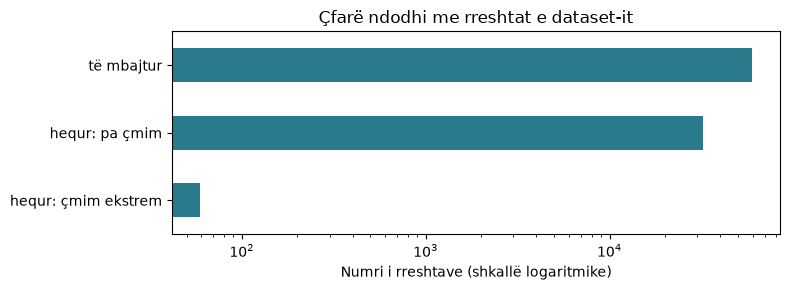

In [45]:
fate = pd.Series({"të mbajtur": len(df), **{f"hequr: {reason}": count for reason, count in removed.items()}})
assert fate.sum() == len(raw), "Çdo rresht duhet të jetë i mbajtur ose i hequr"
display(fate.to_frame("rreshta"))
ax = fate[fate.gt(0)].sort_values().plot.barh(figsize=(8, 3), color="#287a8c")
ax.set(xscale="log", xlabel="Numri i rreshtave (shkallë logaritmike)", title="Çfarë ndodhi me rreshtat e dataset-it")
plt.tight_layout()
plt.show()

### 7.3 Strategjia për mungesat, kolonë për kolonë

Tabela ka një rresht për çdo kolonë që kishte mungesa në dataset-in origjinal, me vendimin dhe arsyen. `veprimi` është njëri nga:
- `kolonë e hequr`: kolona ishte krejt bosh dhe u hoq;
- `plotësuar`: mungesat u plotësuan me një rregull të shpjeguar;
- `rreshta të hequr`: mungesat ishin vetëm te rreshtat e hequr, ndaj te rreshtat e mbajtur nuk mbeti asnjë;
- `lënë bosh`: mungesat u lanë me qëllim.

`mungesa para` dhe `% para` numërojnë të gjitha rreshtat fillestarë; `mungesa pas` dhe `% pas` numërojnë vetëm rreshtat e mbajtur. Kolonat që nuk kishin asnjë mungesë nuk kanë nevojë për vendim dhe mbeten siç janë.

39 nga 93 kolona nuk kishin asnjë mungesë; tabela më poshtë ka 54 kolonat me mungesa.


,kolona
veprimi,
kolonë e hequr,14
plotësuar,6
rreshta të hequr,10
lënë bosh,24


,mungesa para,% para,mungesa pas,% pas,veprimi,arsyeja
neighborhood_overview,91954,100.0,—,—,kolonë e hequr,"kolona është 100% bosh, pa asnjë informacion"
host_since,91954,100.0,—,—,kolonë e hequr,"kolona është 100% bosh, pa asnjë informacion"
host_response_time,91954,100.0,—,—,kolonë e hequr,"kolona është 100% bosh, pa asnjë informacion"
host_response_rate,91954,100.0,—,—,kolonë e hequr,"kolona është 100% bosh, pa asnjë informacion"
host_acceptance_rate,91954,100.0,—,—,kolonë e hequr,"kolona është 100% bosh, pa asnjë informacion"
host_thumbnail_url,91954,100.0,—,—,kolonë e hequr,"kolona është 100% bosh, pa asnjë informacion"
host_neighbourhood,91954,100.0,—,—,kolonë e hequr,"kolona është 100% bosh, pa asnjë informacion"
host_total_listings_count,91954,100.0,—,—,kolonë e hequr,"kolona është 100% bosh, pa asnjë informacion"
host_verifications,91954,100.0,—,—,kolonë e hequr,"kolona është 100% bosh, pa asnjë informacion"
neighbourhood,91954,100.0,—,—,kolonë e hequr,"kolona është 100% bosh, pa asnjë informacion"


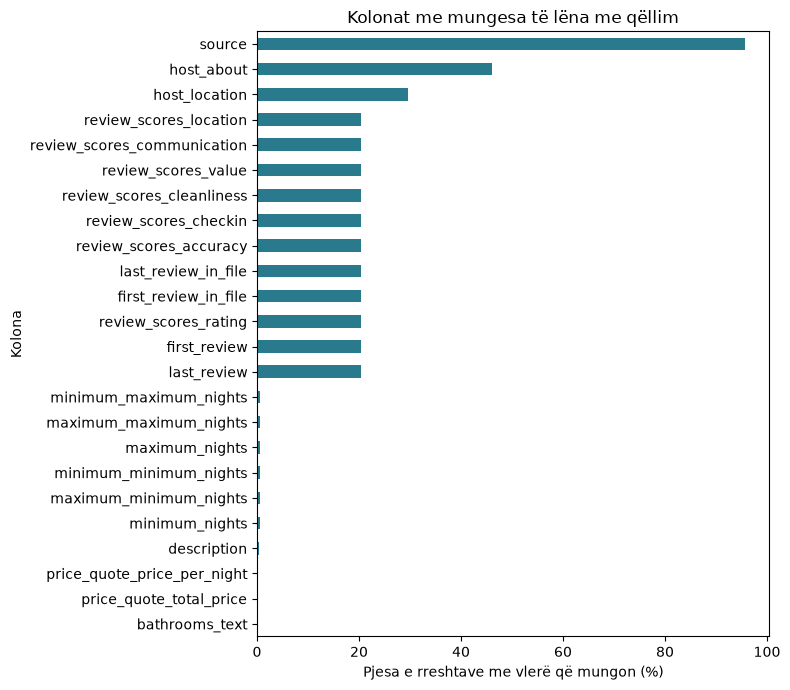

In [46]:
raw_ext = raw.join(joined_snapshot)  # kolonat origjinale plus ato që krijoi bashkimi, para çdo plotësimi

def missing_action(col):
    if col not in df:
        return "kolonë e hequr"
    before = raw_ext.loc[df.index, col].isna().sum()
    after = df[col].isna().sum()
    if after < before:
        return "plotësuar"
    return "rreshta të hequr" if before == 0 else "lënë bosh"

median_fill = "numër; plotësuar me medianën e listimeve me të njëjtin accommodates"
no_reviews = "listimi pa komente nuk ka vlerësim; plotësimi do t'i jepte një notë që nuk e ka marrë kurrë"
no_review_date = "listimi pa komente nuk ka datë; plotësimi do t'i jepte një datë që nuk ka ndodhur"
reasons = {
    "bathrooms": "rindërtuar nga bathrooms_text ('No bathroom' = 0, 'Half-bath' = 0.5); pjesa e mbetur me medianën sipas accommodates",
    "bedrooms": median_fill,
    "beds": median_fill,
    "has_availability": "nxjerrë nga availability_365: True kur listimi ka ditë të lira",
    "reviews_per_month": "listimi pa komente ka 0 komente në muaj; plotësuar me 0 vetëm kur number_of_reviews = 0",
    "price": "variabla që analizojmë; plotësimi do të sajonte çmime, prandaj listimet pa çmim u hoqën",
    "source": "vlera e vetme është 'previous scrape'; boshllëku do të thotë mbledhje e zakonshme, është etiketë",
    "description": "tekst i lirë; nuk plotësohet me tekst të sajuar",
    "host_location": "tekst i lirë që hosti nuk e ka dhënë; analiza e çmimit nuk e përdor",
    "host_about": "tekst i lirë; një biografi e sajuar do të ishte e gabuar",
    "bathrooms_text": "boshllëk i vogël; bathrooms plotësohet me medianë aty ku mungon",
    "price_quote_total_price": "çmimi i një qëndrimi shembull, i nxjerrë nga price; boshllëk i vogël; përjashtohet nga vetitë e modelit",
    "price_quote_price_per_night": "kopje e saktë e price; boshllëk i vogël; përjashtohet nga vetitë e modelit",
    "first_review": no_review_date,
    "last_review": no_review_date,
    "reviews_in_file": "krijuar nga bashkimi me reviews.csv; listimi pa komente në skedar ka 0 komente, jo vlerë të panjohur, prandaj plotësuar me 0",
    "first_review_in_file": "krijuar nga bashkimi me reviews.csv; " + no_review_date,
    "last_review_in_file": "krijuar nga bashkimi me reviews.csv; " + no_review_date,
}
reasons.update({col: no_reviews for col in raw.columns if col.startswith("review_scores_")})
reasons.update({col: "boshllëk i vogël; analiza e çmimit nuk e kërkon dhe një supozim për netët do të ishte i sajuar"
                for col in raw.columns if "nights" in col})

def reason_for(col, action):
    if action == "kolonë e hequr":
        return "kolona është 100% bosh, pa asnjë informacion"
    if action == "rreshta të hequr":
        return reasons.get(col, "mungesat ishin vetëm te rreshtat e hequr (pa çmim), ndaj nuk ka çfarë të plotësohet")
    return reasons[col]  # një kolonë e re me mungesa kërkon një vendim të shkruar këtu

missing_before = raw_ext.isna().sum()
missing_before = missing_before[missing_before.gt(0)]
missing = pd.DataFrame({
    "mungesa para": missing_before,
    "% para": (missing_before / len(raw) * 100).round(1),
    "mungesa pas": df.isna().sum().reindex(missing_before.index).astype("Int64"),
})
missing["% pas"] = (missing["mungesa pas"] / len(df) * 100).astype(float).round(1)
missing["veprimi"] = [missing_action(col) for col in missing.index]
missing["arsyeja"] = [reason_for(col, action) for col, action in zip(missing.index, missing["veprimi"])]
order = {"kolonë e hequr": 0, "plotësuar": 1, "rreshta të hequr": 2, "lënë bosh": 3}
missing = missing.sort_values("veprimi", key=lambda s: s.map(order), kind="stable")

print(f"{raw_ext.shape[1] - len(missing)} nga {raw_ext.shape[1]} kolona nuk kishin asnjë mungesë; tabela më poshtë ka {len(missing)} kolonat me mungesa.")
display(missing.groupby("veprimi").size().reindex(list(order)).to_frame("kolona"))
with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(missing.astype(object).where(missing.notna(), "—"))

kept = missing[missing["veprimi"].eq("lënë bosh")]
ax = (kept["mungesa pas"] / len(df) * 100).sort_values().plot.barh(figsize=(8, 7), color="#287a8c")
ax.set(xlabel="Pjesa e rreshtave me vlerë që mungon (%)", ylabel="Kolona", title="Kolonat me mungesa të lëna me qëllim")
plt.tight_layout()
plt.show()

### 7.4 Kontrollet përfundimtare

Të gjitha vlerat më poshtë duhet të jenë 0. Nëse ndonjëra nuk është, pastrimi ka lënë një problem dhe qeliza ndalon.

In [47]:
no_bathroom = df["bathrooms_text"].str.contains(r"^no bath", case=False, na=False)
checks = pd.Series({
    "çmim që mungon": int(df["price"].isna().sum()),
    "çmim <= 0": int(df["price"].le(0).sum()),
    "ID të dyfishuara": int(df["id"].duplicated().sum()),
    "bathrooms, bedrooms ose beds që mungojnë": int(df[["bathrooms", "bedrooms", "beds"]].isna().sum().sum()),
    "reviews_per_month që mungon": int(df["reviews_per_month"].isna().sum()),
    "has_availability që mungon": int(df["has_availability"].isna().sum()),
    "netë maksimale mbi kufirin": int(df[night_columns].gt(MAX_NIGHTS_CAP).sum().sum()),
    "'No bathroom' me bathrooms jo 0": int(df.loc[no_bathroom, "bathrooms"].ne(0).sum()),
})
display(checks.to_frame("numri"))
assert checks.eq(0).all(), "Pas pastrimit kanë mbetur probleme"

,numri
çmim që mungon,0
çmim <= 0,0
ID të dyfishuara,0
"bathrooms, bedrooms ose beds që mungojnë",0
reviews_per_month që mungon,0
has_availability që mungon,0
netë maksimale mbi kufirin,0
'No bathroom' me bathrooms jo 0,0


### 7.5 Ruajtja

Ruajmë dy skedarë në `dataset/`: `listings_clean_full.csv` (tabela e plotë, hyrja e notebook-ut 03) dhe `listings_preprocessed.csv` (18 kolonat e analizës).

In [48]:
print(f"Rezultati për analizë: {len(analysis):,} rreshta × {analysis.shape[1]} kolona")
print(f"Vlerësime të mungura të ruajtura: {analysis['review_scores_rating'].isna().sum():,}")
output = ROOT / "dataset" / "listings_preprocessed.csv"
full_output = ROOT / "dataset" / "listings_clean_full.csv"
output.parent.mkdir(parents=True, exist_ok=True)
analysis.to_csv(output, index=False)
df.to_csv(full_output, index=False)
print(f"U ruajt: {output.relative_to(ROOT)} ({analysis.shape[1]} kolona)")
print(f"U ruajt: {full_output.relative_to(ROOT)} ({df.shape[1]} kolona)")

Rezultati për analizë: 59,846 rreshta × 18 kolona
Vlerësime të mungura të ruajtura: 12,226
U ruajt: dataset\listings_preprocessed.csv (18 kolona)
U ruajt: dataset\listings_clean_full.csv (87 kolona)


# Pjesa I · 3/4: Krijimi i vetive dhe kodimi

**Qëllimi:** nga tabela e pastruar krijojmë veti të reja që ndihmojnë analizën e çmimit për natë. Pas krijimit, notebook-u vazhdon me diskretizimin, binarizimin dhe kodimin.

**Hyrja:** `dataset/listings_clean_full.csv`, tabela e plotë e pastruar nga notebook-u 02 (të gjitha kolonat, para zgjedhjes së 18 kolonave). Ekzekutoni së pari notebook-un 02. Dataset-i origjinal nuk ndryshohet.

**Dalja:** `dataset/listings_features.csv`, e njëjta tabelë me të gjitha vetitë e reja, për notebook-un 04.

In [49]:
import json
import os
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(os.environ.get("PVDH_PROJECT_ROOT", Path.cwd()))
if not (ROOT / "dataset" / "listings_clean_full.csv").is_file() and (ROOT.parent / "dataset" / "listings_clean_full.csv").is_file():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "dataset" / "listings_clean_full.csv"
assert DATA_PATH.is_file(), f"Mungon {DATA_PATH.name}: ekzekutoni notebook-un 02."
df = pd.read_csv(DATA_PATH, low_memory=False, parse_dates=["last_scraped", "last_review"])
print(f"Hyrja: {DATA_PATH.name} | Rreshta: {len(df):,} | Kolona: {df.shape[1]}")

Hyrja: listings_clean_full.csv | Rreshta: 59,846 | Kolona: 87


## 1. Distanca nga qendra e Londrës

Vendndodhja ndikon fort te çmimi, por `latitude` dhe `longitude` veç e veç nuk kanë kuptim të drejtpërdrejtë. Si qendër marrim **Charing Cross** (51.5073, −0.1276), pikën tradicionale nga e cila maten distancat në Londër. Distancën në km e llogarisim me formulën *haversine*, e cila merr parasysh lakimin e Tokës.

In [50]:
CENTER_LAT, CENTER_LON = 51.5073, -0.1276
EARTH_RADIUS_KM = 6371.0

def haversine_km(lat, lon, lat0, lon0):
    lat, lon, lat0, lon0 = map(np.radians, (lat, lon, lat0, lon0))
    a = np.sin((lat - lat0) / 2) ** 2 + np.cos(lat) * np.cos(lat0) * np.sin((lon - lon0) / 2) ** 2
    return 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(a))

df["distance_to_center_km"] = haversine_km(df["latitude"], df["longitude"], CENTER_LAT, CENTER_LON)
display(df["distance_to_center_km"].describe().round(2).to_frame())
display(df.groupby(pd.cut(df["distance_to_center_km"], [0, 2, 5, 10, 20, 40]), observed=True)["price"].median().to_frame("çmimi median"))

,distance_to_center_km
count,59846.00
mean,7.66
std,5.14
min,0.03
25%,3.84
50%,6.17
75%,10.55
max,30.70


,çmimi median
distance_to_center_km,
"(0, 2]",324.00
"(2, 5]",220.00
"(5, 10]",159.00
"(10, 20]",123.33
"(20, 40]",101.38


## 2. Përvoja e host-it

`hosts_time_as_host_years` jep vitet e plota, ndërsa `hosts_time_as_host_months` muajt e mbetur (0–11). I bashkojmë në një vlerë të vetme në vite.

In [51]:
df["host_tenure_years"] = df["hosts_time_as_host_years"] + df["hosts_time_as_host_months"] / 12
display(df["host_tenure_years"].describe().round(2).to_frame())

,host_tenure_years
count,59846.00
mean,5.37
std,4.06
min,0.00
25%,2.00
50%,4.08
75%,8.83
max,15.67


## 3. Host me shumë listime

`calculated_host_listings_count` numëron listimet e host-it në këtë dataset. E përdorim atë dhe jo `host_listings_count`, sepse ky i fundit vjen nga Airbnb, arrin deri në 5,777 dhe në disa listime është më i vogël se numri i listimeve që shohim vetë në dataset, pra nuk është i qëndrueshëm. Host-i me më shumë se një listim shpesh është menaxher profesional.

In [52]:
df["is_multi_listing_host"] = df["calculated_host_listings_count"].gt(1)
print(f"Listime nga host-e me shumë listime: {df['is_multi_listing_host'].mean():.1%}")
display(df.groupby("is_multi_listing_host")["price"].agg(["count", "median"]).round(2))

Listime nga host-e me shumë listime: 65.5%


,count,median
is_multi_listing_host,,
False,20648,155.0
True,39198,187.0


## 4. Çmimi për person

`price / accommodates` lejon krahasimin e listimeve me kapacitet të ndryshëm. **Kujdes:** kjo veti është krijuar nga çmimi, prandaj nuk duhet përdorur si hyrje e modelit kur çmimi është variabla që parashikohet.

In [53]:
df["price_per_person"] = df["price"] / df["accommodates"]
display(df["price_per_person"].describe().round(2).to_frame())

,price_per_person
count,59846.00
mean,70.99
std,83.94
min,1.50
25%,39.58
50%,55.50
75%,80.83
max,5000.00


## 5. Ditë nga komenti i fundit

Tregon sa aktiv është listimi. Llogaritet nga data e mbledhjes (`last_scraped`) dhe jo nga data e sotme, që rezultati të mos ndryshojë sa herë ekzekutohet notebook-u. Për listimet pa komente vlera mbetet bosh me qëllim: `has_reviews` e mbulon këtë rast.

In [54]:
df["days_since_last_review"] = (df["last_scraped"] - df["last_review"]).dt.days
print(f"Bosh (pa komente): {df['days_since_last_review'].isna().sum():,} | Negative: {int(df['days_since_last_review'].lt(0).sum())}")
display(df["days_since_last_review"].describe().round(1).to_frame())

Bosh (pa komente): 12,226 | Negative: 0


,days_since_last_review
count,47620.0
mean,206.2
std,443.4
min,0.0
25%,16.0
50%,39.0
75%,144.0
max,5289.0


## 6. Kontrolli i vetive të reja

Për secilën veti kontrollojmë mungesat dhe shpërndarjen. `price_per_person` dhe `days_since_last_review` janë shumë asimetrike; kjo trajtohet te transformimi në notebook-un 04.

,bosh
distance_to_center_km,0
host_tenure_years,0
is_multi_listing_host,0
price_per_person,0
days_since_last_review,12226


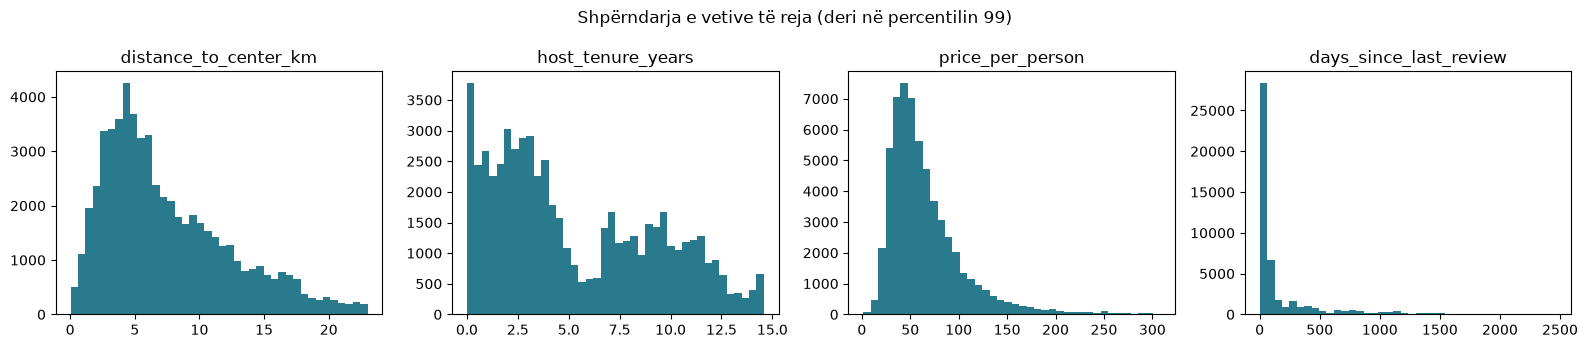

In [55]:
new_features = ["distance_to_center_km", "host_tenure_years", "is_multi_listing_host", "price_per_person", "days_since_last_review"]
display(df[new_features].isna().sum().to_frame("bosh"))
numeric = [col for col in new_features if col != "is_multi_listing_host"]
fig, axes = plt.subplots(1, len(numeric), figsize=(16, 3.5))
for ax, col in zip(axes, numeric):
    values = df[col].dropna()
    values[values.le(values.quantile(0.99))].plot.hist(bins=40, ax=ax, color="#287a8c")
    ax.set(title=col, xlabel="", ylabel="")
fig.suptitle("Shpërndarja e vetive të reja (deri në percentilin 99)")
plt.tight_layout()
plt.show()

## 7. Grupimi i llojit të pronës

`property_type` ka 84 vlera, shumë prej tyre me një ose pak listime. Emri përmban dy informacione: llojin e dhomës dhe llojin e ndërtesës, p.sh. *Private room in rental unit* = `room_type` *Private room* + ndërtesa *rental unit*. Lloji i dhomës ruhet tashmë te `room_type`. Prandaj heqim pjesën e dhomës (*Entire*, *Private room in*, *Shared room in*, *Room in*) dhe grupojmë vetëm **llojin e ndërtesës**. Kështu `property_group` nuk e përsërit `room_type`.

Grupet: **apartment** (banesë, condo, apartament me shërbime, loft), **house** (shtëpi, townhouse, vilë, cottage), **hotel_bnb** (hotel, hostel, aparthotel, bed and breakfast), **guest_suite** (guest suite, guesthouse), **unique** (varkë, kabinë, tendë, kështjellë etj.) dhe **other** për emrat që nuk tregojnë ndërtesën (p.sh. *Entire place*).

In [56]:
ROOM_PREFIX = r"^(entire|private room in|shared room in|room in)\s*"
PROPERTY_GROUPS = {
    "apartment": ["rental unit", "condo", "serviced apartment", "loft", "floor"],
    "house": ["home", "townhouse", "cottage", "bungalow", "villa", "vacation home", "chalet", "earthen home", "cycladic home"],
    "hotel_bnb": ["hotel", "boutique hotel", "aparthotel", "hostel", "bed and breakfast", "casa particular"],
    "guest_suite": ["guest suite", "guesthouse"],
    "unique": ["boat", "houseboat", "tiny home", "cabin", "hut", "shepherd's hut", "camper/rv", "tent", "yurt", "dome",
               "treehouse", "castle", "tower", "lighthouse", "island", "barn", "farm stay", "campsite", "religious building"],
}
group_of = {building: group for group, buildings in PROPERTY_GROUPS.items() for building in buildings}
building = (df["property_type"].str.lower().str.replace("’", "'", regex=False)
            .str.replace(ROOM_PREFIX, "", regex=True).str.strip())
df["property_group"] = building.map(group_of).fillna("other")

print(f"property_type: {df['property_type'].nunique()} vlera → property_group: {df['property_group'].nunique()} grupe")
display(df.groupby("property_group").agg(lloje_origjinale=("property_type", "nunique"), listime=("price", "size"),
                                         cmimi_median=("price", "median")).sort_values("listime", ascending=False))
print("Në 'other':", ", ".join(sorted(df.loc[df["property_group"].eq("other"), "property_type"].unique())))
display(pd.crosstab(df["property_group"], df["room_type"]))

property_type: 84 vlera → property_group: 6 grupe


,lloje_origjinale,listime,cmimi_median
property_group,,,
apartment,14,42143,188.0
house,18,14511,124.0
hotel_bnb,12,2097,126.0
guest_suite,5,760,105.0
unique,32,231,135.0
other,3,104,131.0


Në 'other': Entire home/apt, Entire place, Private room


room_type,Entire home/apt,Hotel room,Private room,Shared room
property_group,,,,
apartment,33275,41,8789,38
guest_suite,329,0,420,11
hotel_bnb,39,93,1878,87
house,6597,0,7887,27
other,55,0,49,0
unique,186,0,44,1


## 8. Pajisjet (`amenities`)

`amenities` është listë JSON e ruajtur si tekst, p.sh. `["Wifi", "Kitchen", ...]`. Notebook-u 02 e numëronte duke numëruar thonjëzat (`"`) dhe duke pjesëtuar me 2. Kjo gabon kur vetë emri i pajisjes përmban thonjëza, p.sh. `"portable stove" stove`. Tani e lexojmë listën me `json.loads` dhe numërojmë elementet.

In [57]:
amenity_lists = df["amenities"].fillna("[]").map(json.loads)
old_count = df["amenities"].fillna("[]").astype(str).str.count('"') // 2
df["amenity_count"] = amenity_lists.map(len)
wrong = old_count.ne(df["amenity_count"])
print(f"Listime me numër të gabuar me metodën e vjetër: {int(wrong.sum())}")
display(pd.DataFrame({"id": df.loc[wrong, "id"], "numri i vjetër": old_count[wrong], "numri i ri": df.loc[wrong, "amenity_count"],
                      "pajisjet me thonjëza": amenity_lists[wrong].map(lambda items: [a for a in items if '"' in a])}))
display(df["amenity_count"].describe().round(1).to_frame())

Listime me numër të gabuar me metodën e vjetër: 3


,id,numri i vjetër,numri i ri,pajisjet me thonjëza
12784,649735327677645022,52,49,"[""Various"" conditioner, ""Various"" body soap, ""..."
14513,689168826164538384,38,37,"[""portable stove"" stove]"
14514,689176861999188774,37,36,"[""portable stove"" electric stove]"


,amenity_count
count,59846.0
mean,32.0
std,15.0
min,0.0
25%,20.0
50%,33.0
75%,43.0
max,99.0


### Flamujt e pajisjeve

Ka mbi 7,000 emra të ndryshëm pajisjesh, sepse host-et i shkruajnë ndryshe (*Wifi*, *Fast wifi – 73 Mbps*, *Pocket wifi*). Për secilin flamur kërkojmë fjalë kyçe në emrat me shkronja të vogla:

- `has_kitchen`: vetëm *Kitchen* ose *Kitchenette*, jo *Outdoor kitchen*;
- `has_washer`: lavatriçe rrobash, jo *Dishwasher*;
- `has_parking`: parking **në pronë** (falas ose me pagesë); parkingu në rrugë ose jashtë pronës nuk llogaritet;
- `has_ac`: *Air conditioning* në çdo formë, *Window AC unit*, *AC - split type*.

Tabela krahason çmimin median të listimeve me dhe pa pajisjen. Ky është krahasim përshkrues, jo shkak-pasojë: p.sh. parkingu është më i shpeshtë larg qendrës, ku çmimet janë më të ulëta.

,% e listimeve,çmimi median me,çmimi median pa
has_wifi,97.5,176.00,126.330
has_kitchen,89.8,184.30,101.000
has_heating,85.1,183.20,123.200
has_washer,84.4,189.00,111.000
has_tv,80.0,199.33,88.790
has_workspace,52.0,185.00,165.000
has_parking,33.0,160.00,180.265
has_ac,14.3,304.00,161.330


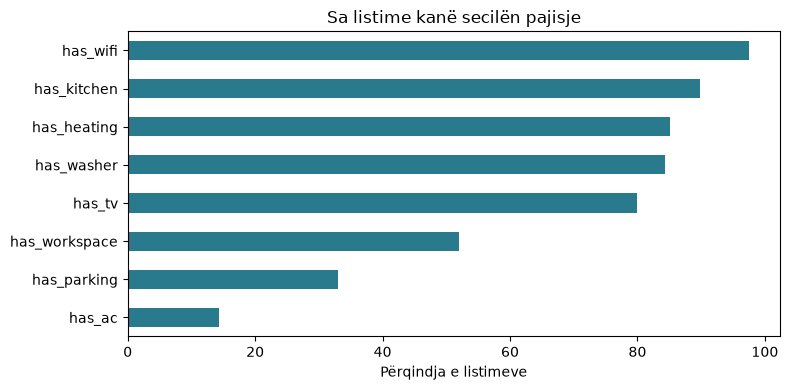

In [58]:
AMENITY_FLAGS = {
    "has_wifi": r"wifi",
    "has_kitchen": r"^(?:kitchen|kitchenette)$",
    "has_ac": r"air conditioning|\bac\b",
    "has_heating": r"heating",
    "has_washer": r"(?<!dish)washer",
    "has_parking": r"parking.*on premises",
    "has_tv": r"\b(?:hd)?tv\b",
    "has_workspace": r"dedicated workspace",
}
amenity_text = amenity_lists.map(lambda items: "\n".join(items).lower())
for flag, pattern in AMENITY_FLAGS.items():
    df[flag] = amenity_text.str.contains(pattern, flags=re.MULTILINE, regex=True)

flags = list(AMENITY_FLAGS)
summary = pd.DataFrame({
    "% e listimeve": df[flags].mean().mul(100).round(1),
    "çmimi median me": [df.loc[df[flag], "price"].median() for flag in flags],
    "çmimi median pa": [df.loc[~df[flag], "price"].median() for flag in flags],
}).sort_values("% e listimeve", ascending=False)
display(summary)
ax = summary["% e listimeve"].sort_values().plot.barh(figsize=(8, 4), color="#287a8c")
ax.set(xlabel="Përqindja e listimeve", ylabel="", title="Sa listime kanë secilën pajisje")
plt.tight_layout()
plt.show()

## 9. Diskretizimi

Diskretizimi e kthen një kolonë numerike në pak grupe. Krahasojmë tri metoda me 4 grupe te `minimum_nights`, `accommodates` dhe `availability_365`:

- **gjerësi e barabartë** (`pd.cut`): intervale me të njëjtën gjatësi;
- **frekuencë e barabartë** (`pd.qcut`): afërsisht i njëjti numër listimesh në çdo grup;
- **sipas domenit**: kufij me kuptim praktik:
  - `minimum_nights`: 1 natë / 2–6 / 7–29 / 30+ (30+ do të thotë qëndrim i gjatë, jo turizëm i shkurtër);
  - `accommodates`: 1 / 2 / 3–4 / 5–6 / 7+ (një person, çift, familje e vogël, familje, grup);
  - `availability_365`: 0 / 1–90 / 91–180 / 181–365 ditë. 90 është kufiri ligjor në Londër për dhënien me qira të një shtëpie të plotë pa leje planifikimi.

`minimum_nights` ka disa vlera që mungojnë pas pastrimit; ato mbeten bosh edhe në grup.

grupe  grupi më i madh (%)  bosh
kolona           metoda                                                 
minimum_nights   gjerësi e barabartë        4                 99.8   298
                 frekuencë e barabartë      3                 69.2   298
                 sipas domenit              4                 47.7   298
accommodates     gjerësi e barabartë        4                 75.0     0
                 frekuencë e barabartë      4                 46.4     0
                 sipas domenit              5                 36.0     0
availability_365 gjerësi e barabartë        4                 42.9     0
                 frekuencë e barabartë      4                 25.1     0
                 sipas domenit              4                 61.2     0

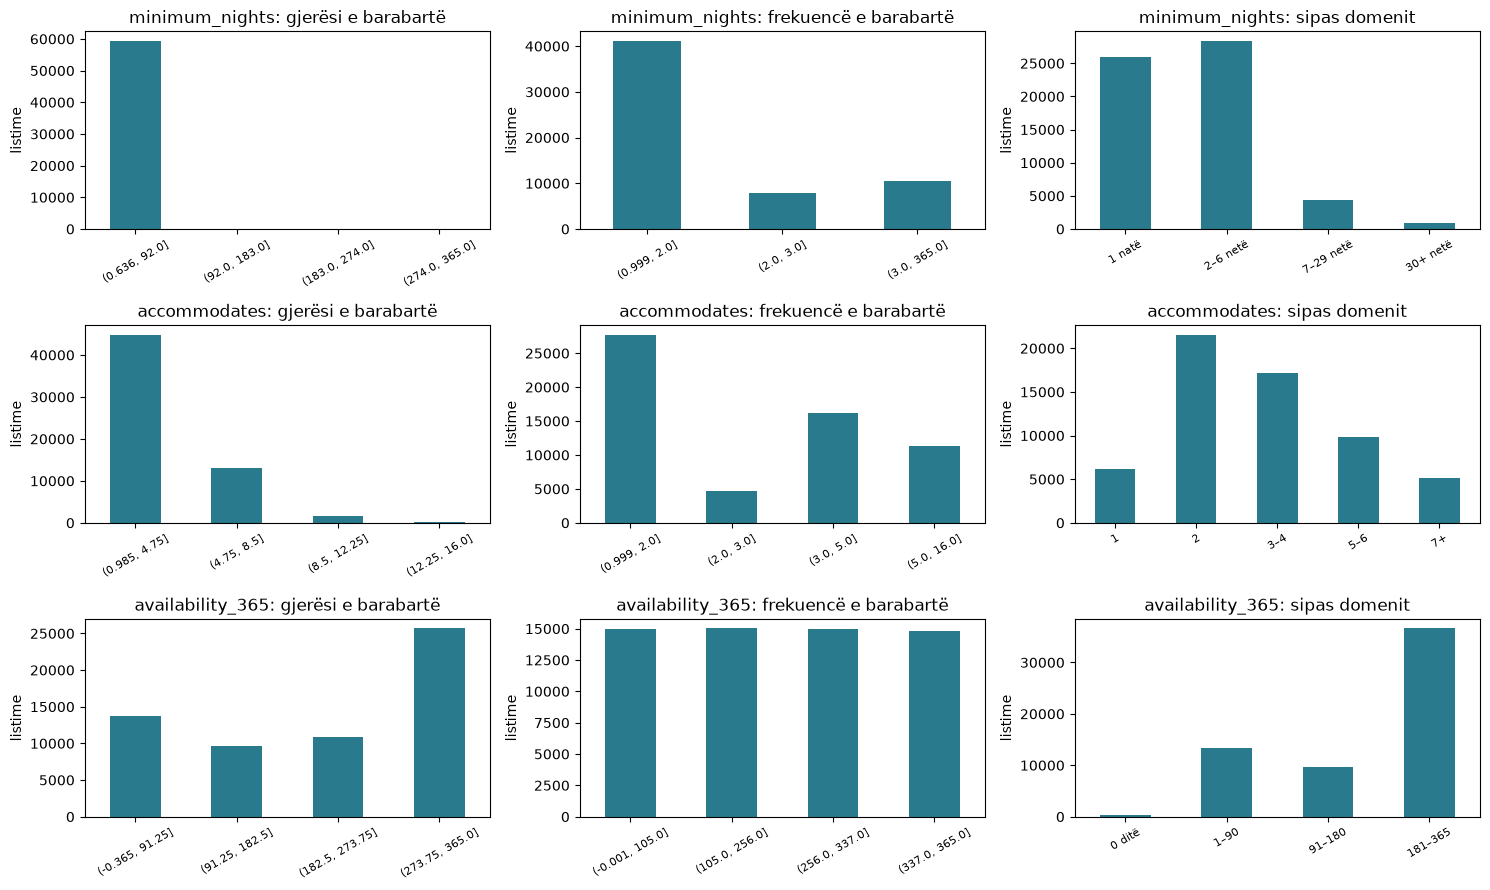

In [59]:
DOMAIN_BINS = {
    "minimum_nights": ([0, 1, 6, 29, np.inf], ["1 natë", "2–6 netë", "7–29 netë", "30+ netë"]),
    "accommodates": ([0, 1, 2, 4, 6, np.inf], ["1", "2", "3–4", "5–6", "7+"]),
    "availability_365": ([-1, 0, 90, 180, 365], ["0 ditë", "1–90", "91–180", "181–365"]),
}
binned = {}
for col, (edges, labels) in DOMAIN_BINS.items():
    binned[col] = {
        "gjerësi e barabartë": pd.cut(df[col], bins=4),
        "frekuencë e barabartë": pd.qcut(df[col], q=4, duplicates="drop"),
        "sipas domenit": pd.cut(df[col], bins=edges, labels=labels),
    }
    df[f"{col}_cat"] = binned[col]["sipas domenit"]

summary = pd.DataFrame([
    {"kolona": col, "metoda": method, "grupe": values.cat.categories.size,
     "grupi më i madh (%)": round(values.value_counts(normalize=True).max() * 100, 1), "bosh": int(values.isna().sum())}
    for col, methods in binned.items() for method, values in methods.items()
]).set_index(["kolona", "metoda"])
display(summary)

fig, axes = plt.subplots(len(binned), 3, figsize=(15, 9))
for row, (col, methods) in zip(axes, binned.items()):
    for ax, (method, values) in zip(row, methods.items()):
        values.value_counts(sort=False).plot.bar(ax=ax, color="#287a8c")
        ax.set(title=f"{col}: {method}", xlabel="", ylabel="listime")
        ax.tick_params(axis="x", rotation=30, labelsize=8)
plt.tight_layout()
plt.show()

**Cila metodë?** Te kolonat shumë asimetrike, gjerësia e barabartë fut pothuajse të gjitha listimet në grupin e parë. Frekuenca e barabartë humbet grupe kur shumë listime kanë të njëjtën vlerë (p.sh. `minimum_nights` = 1). Te `availability_365`, që nuk është asimetrike, gjerësia e barabartë funksionon mirë, ndërsa grupet sipas domenit janë më pak të balancuara (shumica e listimeve kanë mbi 180 ditë të lira). Prandaj si veti finale ruajmë **grupet sipas domenit** (`*_cat`) për shkak të kuptimit, jo të balancës: kufijtë (1 natë, 30+ netë, 90 ditë) kanë kuptim praktik dhe nuk varen nga shpërndarja e këtij dataset-i. Tabela më poshtë tregon çmimin median për secilin grup, si kontroll përshkrues.

In [60]:
for col in DOMAIN_BINS:
    display(df.groupby(f"{col}_cat", observed=True)["price"].agg(listime="size", cmimi_median="median").round(2))

,listime,cmimi_median
minimum_nights_cat,,
1 natë,25875,150.00
2–6 netë,28402,196.69
7–29 netë,4343,170.10
30+ netë,928,128.39


,listime,cmimi_median
accommodates_cat,,
1,6172,65.00
2,21573,118.00
3–4,17122,205.00
5–6,9791,280.00
7+,5188,365.58


,listime,cmimi_median
availability_365_cat,,
0 ditë,305,153.33
1–90,13307,158.57
91–180,9612,178.50
181–365,36622,180.00


### `price_band` si bazë krahasimi

`price_band` u krijua në notebook-un 02 me **frekuencë të barabartë** (tercile të çmimit): tri grupe me afërsisht të njëjtin numër listimesh. E ruajmë si shembull të diskretizimit të çmimit. **Kujdes:** është krijuar nga çmimi, ndaj nuk përdoret si hyrje e modelit kur parashikohet çmimi.

In [61]:
band_order = ["i ulët", "mesatar", "i lartë"]
display(df.groupby("price_band")["price"].agg(listime="size", min="min", max="max").reindex(band_order))

,listime,min,max
price_band,,,
i ulët,19981,10.00,123.0
mesatar,19923,123.02,237.0
i lartë,19942,237.07,6798.4


## 10. Binarizimi

Kolonat logjike (*po/jo*) i kthejmë në **0/1**, formën që e kërkojnë metodat numerike. Pas pastrimit në notebook-un 02 ato nuk kanë më vlera që mungojnë: mungesat ishin vetëm te rreshtat pa çmim. Kontrolli më poshtë e verifikon këtë; një mungesë e re do të mbetej bosh dhe nuk do të bëhej 0.

Binarizimi mund të bëhet edhe me prag mbi një kolonë numerike: `is_long_stay` = 1 kur `minimum_nights` ≥ 30.

`is_superhost` (nga notebook-u 02) është kopje e `host_is_superhost`. Një nga të dyja hiqet te zgjedhja e vetive në notebook-un 04.

In [62]:
BINARY_COLUMNS = ["has_reviews", "is_superhost", "has_availability", "host_identity_verified", "is_multi_listing_host", *AMENITY_FLAGS]
print(f"Vlera që mungojnë te kolonat binare: {int(df[BINARY_COLUMNS].isna().sum().sum())}")
print(f"is_superhost është identike me host_is_superhost: {df['is_superhost'].astype('boolean').equals(df['host_is_superhost'].astype('boolean'))}")
df[BINARY_COLUMNS] = df[BINARY_COLUMNS].astype("boolean").astype("Int8")
df["is_long_stay"] = df["minimum_nights"].ge(30).astype("Int8").mask(df["minimum_nights"].isna())

binary = BINARY_COLUMNS + ["is_long_stay"]
display(pd.DataFrame({"% me vlerën 1": df[binary].mean().mul(100).round(1), "bosh": df[binary].isna().sum()}))

Vlera që mungojnë te kolonat binare: 0
is_superhost është identike me host_is_superhost: True


,% me vlerën 1,bosh
has_reviews,79.6,0
is_superhost,25.0,0
has_availability,99.4,0
host_identity_verified,98.4,0
is_multi_listing_host,65.5,0
has_wifi,97.5,0
has_kitchen,89.8,0
has_ac,14.3,0
has_heating,85.1,0
has_washer,84.4,0


## 11. Kodimi i kategorive

**One-hot** për `room_type` (4 vlera) dhe `property_group` (6 grupe): çdo vlerë bëhet kolonë 0/1. Në çdo rresht vetëm një kolonë e grupit ka 1. Për një model linear duhet hequr një kolonë për grup (*dummy trap*), sepse përndryshe kolonat e grupit mblidhen gjithmonë në 1; vendimi merret te zgjedhja e vetive.

**Lagjja (`neighbourhood_cleansed`, 33 vlera):** one-hot do të shtonte 33 kolona, shumica me pak listime. Kodimi sipas çmimit (*target encoding*) nuk lejohet, sepse fut vetë çmimin në hyrje. Prandaj zgjedhim:

- `is_inner_london`: 1 për 13 lagjet e Londrës së Brendshme sipas *London Government Act 1963* (12 lagje dhe City of London);
- `borough_frequency`: pjesa e listimeve të dataset-it që janë në atë lagje (*frequency encoding*). Për një model, edhe kjo duhet llogaritur vetëm në setin e trajnimit.

Emri i lagjes ruhet si kategori për agregime.

In [63]:
one_hot = pd.get_dummies(df[["room_type", "property_group"]], prefix=["room", "property"], dtype="int8")
one_hot.columns = one_hot.columns.str.lower().str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_")
df = pd.concat([df, one_hot], axis=1)
print(f"Kolona one-hot: {one_hot.shape[1]} | çdo rresht ka saktësisht 1 për grup: "
      f"{bool(one_hot.filter(like='room_').sum(axis=1).eq(1).all() and one_hot.filter(like='property_').sum(axis=1).eq(1).all())}")
display(one_hot.sum().to_frame("listime"))

INNER_LONDON = {"Camden", "City of London", "Greenwich", "Hackney", "Hammersmith and Fulham", "Islington", "Kensington and Chelsea",
                "Lambeth", "Lewisham", "Southwark", "Tower Hamlets", "Wandsworth", "Westminster"}
missing_names = INNER_LONDON - set(df["neighbourhood_cleansed"])
assert not missing_names, f"Emra lagjesh që nuk gjenden: {missing_names}"
df["is_inner_london"] = df["neighbourhood_cleansed"].isin(INNER_LONDON).astype("Int8")
df["borough_frequency"] = df["neighbourhood_cleansed"].map(df["neighbourhood_cleansed"].value_counts(normalize=True))

boroughs = df.groupby("neighbourhood_cleansed").agg(
    listime=("id", "size"), borough_frequency=("borough_frequency", "first"), is_inner_london=("is_inner_london", "first"),
    km_nga_qendra=("distance_to_center_km", "median"), cmimi_median=("price", "median"),
).sort_values("listime", ascending=False)
display(boroughs.round(3))
display(df.groupby("is_inner_london").agg(listime=("id", "size"), km_nga_qendra=("distance_to_center_km", "median"),
                                          cmimi_median=("price", "median")).round(2))

Kolona one-hot: 10 | çdo rresht ka saktësisht 1 për grup: True


,listime
room_entire_home_apt,40481
room_hotel_room,134
room_private_room,19067
room_shared_room,164
property_apartment,42143
property_guest_suite,760
property_hotel_bnb,2097
property_house,14511
property_other,104
property_unique,231


,listime,borough_frequency,is_inner_london,km_nga_qendra,cmimi_median
neighbourhood_cleansed,,,,,
Westminster,7942,0.133,1,2.661,281.550
Kensington and Chelsea,4648,0.078,1,4.612,272.500
Camden,4291,0.072,1,2.938,207.500
Tower Hamlets,3875,0.065,1,5.692,161.500
Southwark,3029,0.051,1,3.810,157.670
Lambeth,2829,0.047,1,4.432,153.000
Hackney,2826,0.047,1,6.153,164.380
Wandsworth,2691,0.045,1,6.778,185.090
Hammersmith and Fulham,2680,0.045,1,6.393,184.000


,listime,km_nga_qendra,cmimi_median
is_inner_london,,,
0,19285,12.42,125.0
1,40561,4.58,200.0


## 12. Ruajtja

Ruajmë tabelën e plotë me të gjitha vetitë e reja për notebook-un 04. Kolonat origjinale mbeten; zgjedhja e nënbashkësisë bëhet te reduktimi i dimensionit.

In [64]:
new_columns = df.columns.difference(pd.read_csv(DATA_PATH, nrows=0).columns)
output = ROOT / "dataset" / "listings_features.csv"
df.to_csv(output, index=False)
print(f"U ruajt: {output.relative_to(ROOT)} ({len(df):,} rreshta × {df.shape[1]} kolona, nga të cilat {len(new_columns)} të reja)")
print("Kolonat e reja:", ", ".join(sorted(new_columns)))

U ruajt: dataset\listings_features.csv (59,846 rreshta × 117 kolona, nga të cilat 30 të reja)
Kolonat e reja: accommodates_cat, availability_365_cat, borough_frequency, days_since_last_review, distance_to_center_km, has_ac, has_heating, has_kitchen, has_parking, has_tv, has_washer, has_wifi, has_workspace, host_tenure_years, is_inner_london, is_long_stay, is_multi_listing_host, minimum_nights_cat, price_per_person, property_apartment, property_group, property_guest_suite, property_hotel_bnb, property_house, property_other, property_unique, room_entire_home_apt, room_hotel_room, room_private_room, room_shared_room


**Vazhdon në notebook-un 04:** transformimi (logaritmi, normalizimi dhe standardizimi) dhe reduktimi i dimensionit.

# Pjesa I · 4/4: Transformimi dhe reduktimi i dimensionit

**Qëllimi:** të përgatisim vetitë numerike për metodat që varen nga shkalla dhe shpërndarja e vlerave (korrelacioni, PCA, modelet). Së pari matim sa asimetrike janë kolonat, pastaj i transformojmë (logaritmi, rrënja katrore) dhe i shkallëzojmë (min-max, z-score). Në fund zgjedhim nënbashkësinë e vetive dhe zvogëlojmë dimensionin.

**Hyrja:** `dataset/listings_features.csv`, tabela me vetitë e reja nga notebook-u 03. Ekzekutoni së pari notebook-et 02 dhe 03.

**Dalja:** `dataset/listings_transformed.csv`, e njëjta tabelë me kolonat e transformuara (`_log`, `_sqrt`) dhe të shkallëzuara (`_minmax`, `_z`).

**Dalja finale:** `dataset/listings_model_ready.csv`, nënbashkësia e zgjedhur e vetive (seksioni 8).

In [65]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(os.environ.get("PVDH_PROJECT_ROOT", Path.cwd()))
if not (ROOT / "dataset" / "listings_features.csv").is_file() and (ROOT.parent / "dataset" / "listings_features.csv").is_file():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "dataset" / "listings_features.csv"
assert DATA_PATH.is_file(), f"Mungon {DATA_PATH.name}: ekzekutoni notebook-un 03."
df = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Hyrja: {DATA_PATH.name} | Rreshta: {len(df):,} | Kolona: {df.shape[1]}")

Hyrja: listings_features.csv | Rreshta: 59,846 | Kolona: 117


## 1. Asimetria para transformimit

**Asimetria** (*skewness*) tregon sa e zhvendosur është shpërndarja. Vlera pozitive do të thotë një "bisht" i gjatë djathtas: shumica e listimeve kanë vlera të vogla dhe pak listime kanë vlera shumë të mëdha (p.sh. pak host-e me qindra listime). Kjo ka rëndësi sepse:

- mesatarja dhe devijimi standard tërhiqen nga vlerat e mëdha;
- korrelacioni dhe PCA i japin peshë të tepërt atyre pak vlerave;
- standardizimi (z-score) nuk e ndreq asimetrinë, vetëm e zhvendos dhe e shkallëzon.

Rregulli i zakonshëm: |asimetria| < 0.5 është afërsisht simetrike, 0.5–1 mesatarisht asimetrike dhe > 1 shumë asimetrike.

Shqyrtojmë vetitë numerike me kuptim për analizën e çmimit. Nuk përfshijmë ID-të, koordinatat, kolonat 0/1 (binare dhe one-hot) dhe kolonat `price_quote_*`, që janë kopje të çmimit.

,asimetria,kategoria,min,mediana,mesatarja,max,bosh
price_per_person,17.93,shumë asimetrike,1.50,55.50,70.99,5000.00,0
minimum_nights,16.47,shumë asimetrike,1.00,2.00,3.73,365.00,298
host_listings_count,10.61,shumë asimetrike,0.00,4.00,68.08,5777.00,0
price,8.31,shumë asimetrike,10.00,175.00,237.16,6798.40,0
calculated_host_listings_count,7.05,shumë asimetrike,1.00,3.00,18.47,501.00,0
number_of_reviews_ltm,6.38,shumë asimetrike,0.00,3.00,8.87,789.00,0
number_of_reviews,5.49,shumë asimetrike,0.00,8.00,31.22,1705.00,0
reviews_per_month,4.69,shumë asimetrike,0.00,0.54,1.09,55.84,0
bathrooms,4.48,shumë asimetrike,0.00,1.00,1.35,30.00,0
days_since_last_review,4.04,shumë asimetrike,0.00,39.00,206.20,5289.00,12226


kategoria
shumë asimetrike          15
simetrike                  3
mesatarisht asimetrike     2


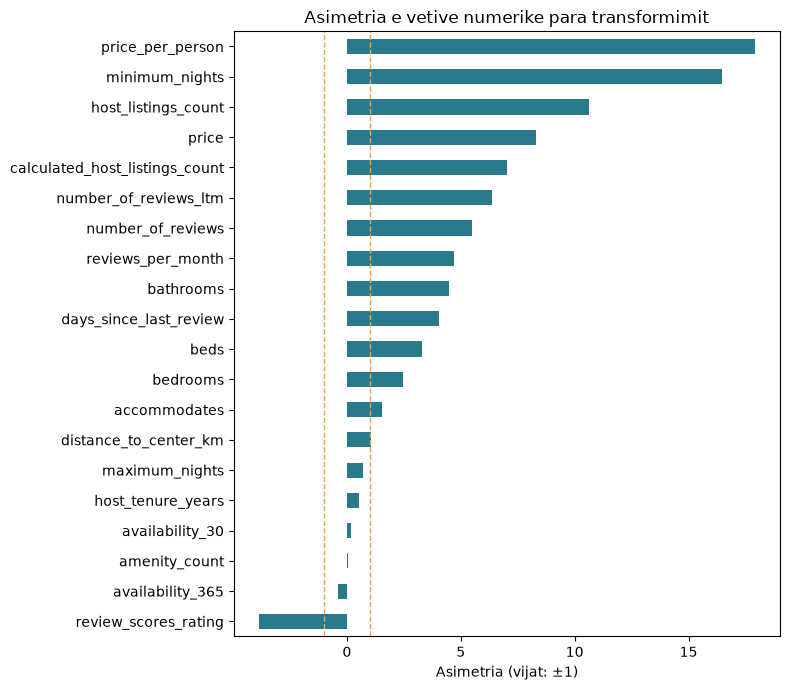

In [66]:
NUMERIC_FEATURES = [
    "price", "price_per_person", "accommodates", "bathrooms", "bedrooms", "beds", "minimum_nights", "maximum_nights",
    "availability_30", "availability_365", "number_of_reviews", "number_of_reviews_ltm", "reviews_per_month",
    "review_scores_rating", "host_listings_count", "calculated_host_listings_count", "host_tenure_years",
    "distance_to_center_km", "amenity_count", "days_since_last_review",
]
missing_columns = [col for col in NUMERIC_FEATURES if col not in df]
assert not missing_columns, f"Mungojnë kolonat: {missing_columns}"

def skew_label(value):
    if abs(value) < 0.5:
        return "simetrike"
    return "mesatarisht asimetrike" if abs(value) <= 1 else "shumë asimetrike"

skew_before = df[NUMERIC_FEATURES].skew()
skew_table = pd.DataFrame({
    "asimetria": skew_before.round(2),
    "kategoria": skew_before.map(skew_label),
    "min": df[NUMERIC_FEATURES].min(),
    "mediana": df[NUMERIC_FEATURES].median(),
    "mesatarja": df[NUMERIC_FEATURES].mean().round(2),
    "max": df[NUMERIC_FEATURES].max(),
    "bosh": df[NUMERIC_FEATURES].isna().sum(),
}).round(2).sort_values("asimetria", ascending=False)
display(skew_table)
print(skew_table["kategoria"].value_counts().to_string())

ax = skew_before.sort_values().plot.barh(figsize=(8, 7), color="#287a8c")
for limit in (-1, 1):
    ax.axvline(limit, color="#e4a64c", linestyle="--", linewidth=1)
ax.set(xlabel="Asimetria (vijat: ±1)", ylabel="", title="Asimetria e vetive numerike para transformimit")
plt.tight_layout()
plt.show()

**Përfundim.** Kolonat me asimetri pozitive mbi 1 janë kandidate për transformim në seksionin 2. Te shumica e tyre mesatarja është shumë më e madhe se mediana, shenjë e bishtit të gjatë djathtas. `review_scores_rating` ka asimetri **negative**: shumica e notave janë afër maksimumit 5. Logaritmi nuk e ndihmon këtë rast, sepse ngjesh vlerat e mëdha, ndërsa këtu bishti është majtas; prandaj kjo kolonë nuk transformohet.

## 2. Transformimi me logaritëm dhe rrënjë katrore

Për kolonat me asimetri pozitive mbi 1 provojmë dy transformime që ngjeshin vlerat e mëdha:

- **logaritmi** `log1p(x) = log(1 + x)`: ngjeshje e fortë. Përdorim `log1p` dhe jo `log`, sepse shumë kolona kanë vlerën 0 (p.sh. listime pa komente) dhe `log(0)` nuk është i përcaktuar;
- **rrënja katrore** `sqrt(x)`: ngjeshje më e butë, e mjaftueshme për kolonat pak asimetrike.

Për secilën kolonë zgjedhim transformimin që e afron asimetrinë më shumë me 0. Kolona origjinale mbetet; versioni i transformuar ruhet si kolonë e re me prapashtesën `_log` ose `_sqrt`. Vlerat që mungojnë mbeten bosh.

Për `price`, nëse më vonë një model parashikon `price_log`, rezultati kthehet në çmim me `expm1`, funksionin e anasjelltë të `log1p`.

In [67]:
TRANSFORMS = {"log": np.log1p, "sqrt": np.sqrt}
skewed = skew_before[skew_before.gt(1)].sort_values(ascending=False).index.tolist()

rows = []
for col in skewed:
    skew_after = {name: transform(df[col]).skew() for name, transform in TRANSFORMS.items()}
    best = min(skew_after, key=lambda name: abs(skew_after[name]))
    new_col = f"{col}_{best}"
    df[new_col] = TRANSFORMS[best](df[col])
    rows.append({"kolona": col, "para": skew_before[col], "pas log1p": skew_after["log"], "pas sqrt": skew_after["sqrt"],
                 "zgjedhja": best, "kolona e re": new_col})
transform_table = pd.DataFrame(rows).set_index("kolona").round(2)
display(transform_table)

TRANSFORMED = transform_table["kolona e re"].tolist()
still_skewed = df[TRANSFORMED].skew().loc[lambda s: s.abs() > 1]
print(f"Kolona shumë asimetrike: {len(skewed)} para transformimit → {len(still_skewed)} pas tij")
print("Ende mbi 1:", ", ".join(f"{col} ({value:.2f})" for col, value in still_skewed.items()) or "asnjë")
assert df[TRANSFORMED].isna().sum().equals(df[skewed].isna().sum().set_axis(TRANSFORMED)), "Transformimi nuk duhet të krijojë mungesa të reja"


,para,pas log1p,pas sqrt,zgjedhja,kolona e re
kolona,,,,,
price_per_person,17.93,0.69,3.90,log,price_per_person_log
minimum_nights,16.47,2.36,5.49,log,minimum_nights_log
host_listings_count,10.61,1.43,8.14,log,host_listings_count_log
price,8.31,0.31,2.37,log,price_log
calculated_host_listings_count,7.05,1.04,2.99,log,calculated_host_listings_count_log
number_of_reviews_ltm,6.38,0.41,1.12,log,number_of_reviews_ltm_log
number_of_reviews,5.49,0.20,1.69,log,number_of_reviews_log
reviews_per_month,4.69,0.93,0.81,sqrt,reviews_per_month_sqrt
bathrooms,4.48,1.15,0.99,sqrt,bathrooms_sqrt


Kolona shumë asimetrike: 14 para transformimit → 3 pas tij
Ende mbi 1: minimum_nights_log (2.36), host_listings_count_log (1.43), calculated_host_listings_count_log (1.04)


### Para dhe pas: histogramet

Tri shembuj: çmimi, numri i komenteve dhe numri i listimeve të host-it. Para transformimit, pothuajse të gjitha listimet janë të ngjeshura në shiritin e parë; pas tij shpërndarja shtrihet dhe bëhet afërsisht simetrike.

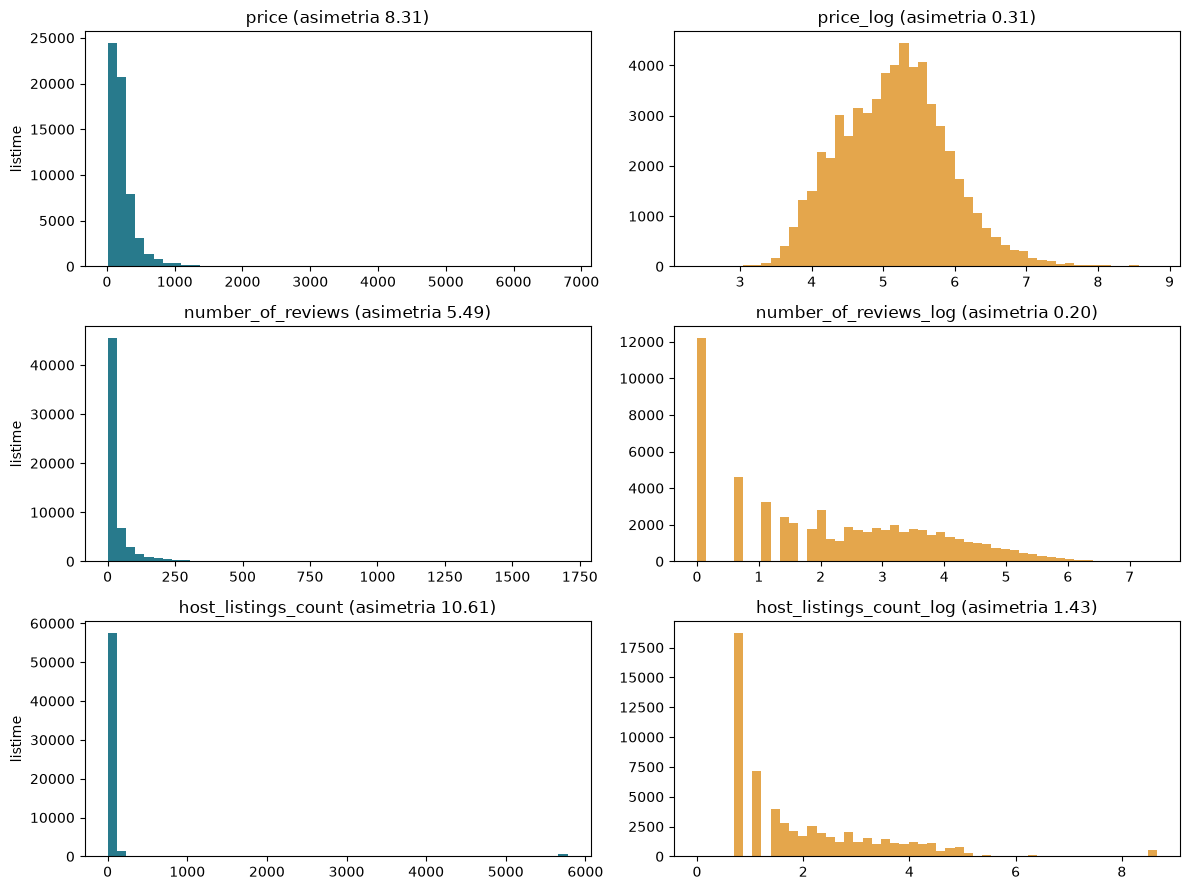

In [68]:
examples = ["price", "number_of_reviews", "host_listings_count"]
fig, axes = plt.subplots(len(examples), 2, figsize=(12, 9))
for (ax_before, ax_after), col in zip(axes, examples):
    new_col = transform_table.loc[col, "kolona e re"]
    df[col].plot.hist(bins=50, ax=ax_before, color="#287a8c")
    ax_before.set(title=f"{col} (asimetria {df[col].skew():.2f})", ylabel="listime")
    df[new_col].plot.hist(bins=50, ax=ax_after, color="#e4a64c")
    ax_after.set(title=f"{new_col} (asimetria {df[new_col].skew():.2f})", ylabel="")
plt.tight_layout()
plt.show()

**Përfundim.** Transformimi e ul fort asimetrinë te shumica e kolonave; `price_log` bëhet afërsisht simetrik. Tri kolona mbeten mbi 1. Te `minimum_nights`, shumica e listimeve kanë saktësisht 1 ose 2 netë, dhe asnjë transformim nuk i ndan vlerat e njëjta; grupet sipas domenit (`minimum_nights_cat`) dhe `is_long_stay` nga notebook-u 03 e përfaqësojnë më mirë. Te dy numrat e listimeve të host-it, pak menaxherë profesionalë kanë qindra listime; `is_multi_listing_host` nga notebook-u 03 e kap këtë dallim në mënyrë më të thjeshtë.

## 3. Shkallëzimi: min-max dhe z-score

Vetitë kanë njësi dhe intervale shumë të ndryshme: `accommodates` shkon nga 1 deri në 16, `availability_365` nga 0 deri në 365. Metodat që llogarisin distanca ose varianca (PCA, k-means, k-NN) do t'u jepnin peshë më të madhe kolonave me numra më të mëdhenj, vetëm për shkak të njësisë. Shkallëzimi i sjell në të njëjtën shkallë.

- **Min-max** `(x − min) / (max − min)`: çdo vlerë bie në intervalin [0, 1]. Është i ndjeshëm ndaj vlerave ekstreme: një vlerë shumë e madhe i ngjesh të gjitha të tjerat afër 0.
- **Z-score** `(x − mesatarja) / devijimi standard`: mesatarja bëhet 0 dhe devijimi standard 1. Vlerat tregojnë sa devijime standarde larg mesatares është listimi. Ky përdoret për PCA.

Shkallëzojmë 20 vetitë numerike të seksionit 1, duke përdorur versionin `_log`/`_sqrt` aty ku kolona u transformua. Shkallëzimi ndryshon vetëm njësinë, jo formën e shpërndarjes; prandaj asimetria mbetet e njëjtë dhe transformimi i seksionit 2 bëhet para tij.

**Kujdes për modelet:** këtu min, max, mesatarja dhe devijimi standard llogariten mbi të gjitha listimet, sepse qëllimi është përshkrues. Për një model parashikues, ato llogariten **vetëm në setin e trajnimit** dhe pastaj zbatohen në setin e testimit. Përndryshe informacioni nga testi rrjedh te trajnimi (*data leakage*).

In [69]:
transformed_name = transform_table["kolona e re"].to_dict()
SCALE_FEATURES = [transformed_name.get(col, col) for col in NUMERIC_FEATURES]
values = df[SCALE_FEATURES].astype(float)

minmax = (values - values.min()) / (values.max() - values.min())
zscore = (values - values.mean()) / values.std(ddof=0)
df[[f"{col}_minmax" for col in SCALE_FEATURES]] = minmax.to_numpy()
df[[f"{col}_z" for col in SCALE_FEATURES]] = zscore.to_numpy()

scaling_check = pd.DataFrame({
    "min para": values.min(), "max para": values.max(),
    "min-max: min": minmax.min(), "min-max: max": minmax.max(),
    "z: mesatarja": zscore.mean(), "z: dev. std.": zscore.std(ddof=0),
    "asimetria para": values.skew(), "asimetria pas z": zscore.skew(),
}).round(2) + 0.0  # + 0.0 shfaq -0.0 si 0.0
display(scaling_check)
assert np.allclose(scaling_check[["min-max: min", "z: mesatarja"]], 0) and np.allclose(scaling_check[["min-max: max", "z: dev. std."]], 1)
assert minmax.isna().sum().equals(values.isna().sum()) and zscore.isna().sum().equals(values.isna().sum()), "Shkallëzimi nuk duhet të krijojë mungesa"
print(f"Kolona të shkallëzuara: {len(SCALE_FEATURES)} × 2 metoda = {2 * len(SCALE_FEATURES)} kolona të reja (_minmax dhe _z)")

,min para,max para,min-max: min,min-max: max,z: mesatarja,z: dev. std.,asimetria para,asimetria pas z
price_log,2.40,8.82,0.0,1.0,0.0,1.0,0.31,0.31
price_per_person_log,0.92,8.52,0.0,1.0,0.0,1.0,0.69,0.69
accommodates_log,0.69,2.83,0.0,1.0,0.0,1.0,0.34,0.34
bathrooms_sqrt,0.00,5.48,0.0,1.0,0.0,1.0,0.99,0.99
bedrooms_sqrt,0.00,5.48,0.0,1.0,0.0,1.0,0.11,0.11
beds_log,0.00,3.93,0.0,1.0,0.0,1.0,0.96,0.96
minimum_nights_log,0.69,5.90,0.0,1.0,0.0,1.0,2.36,2.36
maximum_nights,1.00,1125.00,0.0,1.0,0.0,1.0,0.70,0.70
availability_30,0.00,30.00,0.0,1.0,0.0,1.0,0.20,0.20
availability_365,0.00,365.00,0.0,1.0,0.0,1.0,-0.38,-0.38


Kolona të shkallëzuara: 20 × 2 metoda = 40 kolona të reja (_minmax dhe _z)


### Para dhe pas shkallëzimit

Majtas: vlerat origjinale në shkallë logaritmike, sepse intervalet ndryshojnë shumë. Djathtas: të njëjtat veti pas z-score, tani të krahasueshme në një bosht të përbashkët (pa vlerat ekstreme në grafik).

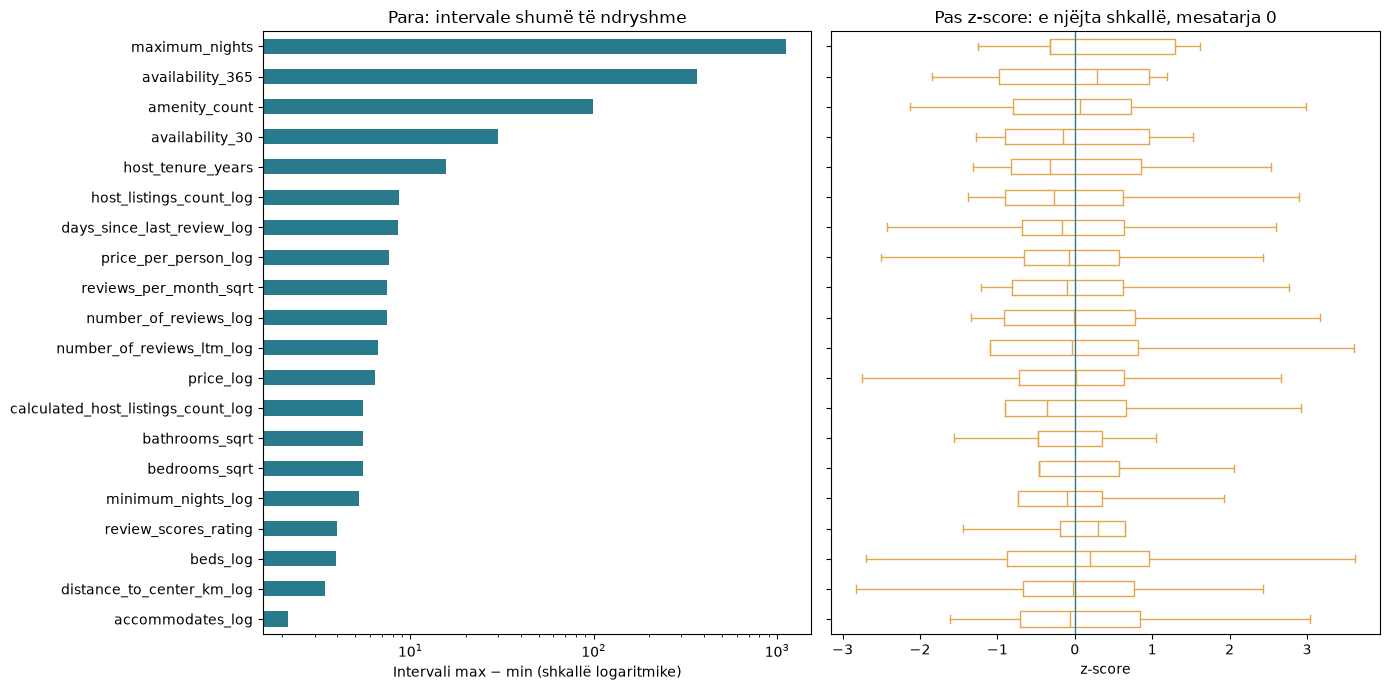

In [70]:
fig, (ax_before, ax_after) = plt.subplots(1, 2, figsize=(14, 7))
ranges = (values.max() - values.min()).sort_values()
ranges.plot.barh(ax=ax_before, color="#287a8c", logx=True)
ax_before.set(xlabel="Intervali max − min (shkallë logaritmike)", ylabel="", title="Para: intervale shumë të ndryshme")
zscore[ranges.index].plot.box(ax=ax_after, vert=False, showfliers=False, color="#e4a64c")
ax_after.axvline(0, color="#287a8c", linewidth=1)
ax_after.set(xlabel="z-score", title="Pas z-score: e njëjta shkallë, mesatarja 0")
ax_after.set_yticklabels([])
plt.tight_layout()
plt.show()

## 4. Ruajtja

Ruajmë tabelën e plotë me kolonat e reja. Kolonat origjinale mbeten, që çdo transformim të mund të krahasohet me vlerat fillestare. Hapi tjetër, zgjedhja e vetive dhe PCA, përdor kolonat `_z`.

In [ ]:
new_columns = df.columns.difference(pd.read_csv(DATA_PATH, nrows=0).columns)
summary = pd.Series({
    "të transformuara (_log, _sqrt)": len(TRANSFORMED),
    "min-max (_minmax)": int(new_columns.str.endswith("_minmax").sum()),
    "z-score (_z)": int(new_columns.str.endswith("_z").sum()),
})
assert summary.sum() == len(new_columns)
display(summary.to_frame("kolona të reja"))

output = ROOT / "dataset" / "listings_transformed.csv"
df.to_csv(output, index=False)
print(f"U ruajt: {output.relative_to(ROOT)} ({len(df):,} rreshta × {df.shape[1]} kolona, nga të cilat {len(new_columns)} të reja)")

,kolona të reja
"të transformuara (_log, _sqrt)",14
min-max (_minmax),20
z-score (_z),20


## 5. Zgjedhja e vetive: korrelacioni

Shumë kolona të dataset-it mbajnë pothuajse të njëjtin informacion, p.sh. disponueshmëria për 30, 60, 90 dhe 365 ditë. Kolonat e tepërta nuk shtojnë informacion, por e rëndojnë analizën dhe i japin peshë të dyfishtë të njëjtit faktor në PCA dhe në modele.

**Kolonat e nxjerra nga çmimi** përjashtohen që në fillim, sepse çmimi është variabla që analizojmë: `price` dhe versionet e tij, `price_per_person`, `price_band`, `price_above_p99`, `price_quote_*` dhe `estimated_revenue_l365d` (= çmimi × netët e zëna). Si hyrje modeli do ta zbulonin vetë përgjigjen (*target leakage*).

Për kolonat e tjera përdorim **korrelacionin e Spearman-it** (ρ). Ai krahason renditjen e vlerave, jo vetë vlerat, ndaj nuk ndikohet nga asimetria dhe vlerat ekstreme. Rezultati është i njëjtë për kolonën origjinale dhe për versionin e saj `_log`/`_sqrt`.

**Rregulli:** brenda çdo grupi kolonash të ngjashme, kolonat renditen sipas kuptimit (e para është ajo që e kupton më lehtë një lexues ose mysafir). Shkojmë me radhë: një kolonë mbahet vetëm nëse |ρ| me çdo kolonë të mbajtur më parë është nën **0.8**, kufiri i zakonshëm për korrelacion shumë të fortë.

In [ ]:
target_derived = [col for col in df.columns if col.startswith(("price", "estimated_revenue"))]
print(f"Kolona të nxjerra nga çmimi, të përjashtuara: {len(target_derived)}")
print(", ".join(col for col in target_derived if not col.endswith(("_minmax", "_z"))))

REDUNDANCY_THRESHOLD = 0.8
REDUNDANCY_GROUPS = {
    "kapaciteti": ["accommodates", "bedrooms", "bathrooms", "beds"],
    "disponueshmëria": ["availability_365", "availability_30", "availability_90", "availability_60", "availability_eoy",
                        "calendar_available_days", "calendar_weekend_availability"],
    "netët minimale": ["minimum_nights", "minimum_nights_avg_ntm", "maximum_minimum_nights", "minimum_minimum_nights"],
    "netët maksimale": ["maximum_nights", "maximum_nights_avg_ntm", "minimum_maximum_nights", "maximum_maximum_nights"],
    "listimet e host-it": ["calculated_host_listings_count", "calculated_host_listings_count_entire_homes",
                           "calculated_host_listings_count_private_rooms", "calculated_host_listings_count_shared_rooms",
                           "host_listings_count"],
    "notat e komenteve": ["review_scores_rating", "review_scores_location", "review_scores_cleanliness", "review_scores_checkin",
                          "review_scores_communication", "review_scores_value", "review_scores_accuracy"],
    "numri i komenteve": ["number_of_reviews", "reviews_per_month", "number_of_reviews_ltm", "number_of_reviews_l30d",
                          "number_of_reviews_ly", "reviews_in_file", "estimated_occupancy_l365d"],
}
missing_columns = [col for cols in REDUNDANCY_GROUPS.values() for col in cols if col not in df]
assert not missing_columns, f"Mungojnë kolonat: {missing_columns}"

group_corr = {}
decisions = []
for group, cols in REDUNDANCY_GROUPS.items():
    rho = df[cols].corr(method="spearman")
    group_corr[group] = rho
    kept = []
    for col in cols:
        partner = rho.loc[col, kept].abs().idxmax() if kept else None
        value = rho.loc[col, partner] if partner else np.nan
        keep = partner is None or abs(value) < REDUNDANCY_THRESHOLD
        if keep:
            kept.append(col)
        decisions.append({"grupi": group, "kolona": col, "vendimi": "mbahet" if keep else "hiqet",
                          "më e lidhura e mbajtur": partner or "—", "ρ": value})
redundancy = pd.DataFrame(decisions).set_index(["grupi", "kolona"]).round(2)
with pd.option_context("display.max_rows", None):
    display(redundancy)
print(redundancy["vendimi"].value_counts().to_string())

print(f"is_superhost është kopje e host_is_superhost: {df['is_superhost'].astype(bool).equals(df['host_is_superhost'].astype(bool))}; mbahet is_superhost (0/1).")

### Matricat e korrelacionit sipas grupit

Ngjyra e errët do të thotë korrelacion i fortë. Katrorët me vlerë afër 1 jashtë diagonales tregojnë kolona që mbajnë të njëjtin informacion.

In [ ]:
fig, axes = plt.subplots(4, 2, figsize=(15, 22))
for ax, (group, rho) in zip(axes.flat, group_corr.items()):
    image = ax.imshow(rho, vmin=-1, vmax=1, cmap="RdBu_r")
    labels = [col.replace("calculated_host_listings_count", "calc_host").replace("review_scores_", "score_") for col in rho.columns]
    ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(labels)), labels, fontsize=8)
    for i in range(len(rho)):
        for j in range(len(rho)):
            ax.text(j, i, f"{rho.iat[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(rho.iat[i, j]) > 0.6 else "black")
    ax.set_title(f"{group} (Spearman ρ)")
axes.flat[-1].axis("off")
fig.colorbar(image, ax=axes, shrink=0.4, label="ρ")
plt.show()

**Përfundim.** Shumica e kolonave të hequra janë variante të së njëjtës matje: `minimum_minimum_nights` dhe `minimum_nights` kanë ρ = 1.00, `reviews_in_file` (nga integrimi) është kopje e `number_of_reviews`, dhe kolonat e kalendarit (`calendar_*`) përputhen me `availability_365`. Te kapaciteti, `beds` hiqet sepse e ndjek nga afër `accommodates`; `bedrooms` dhe `bathrooms` mbeten sepse sjellin informacion shtesë. Notat e komenteve janë të lidhura (0.46–0.81), por vetëm `review_scores_accuracy` e kalon kufirin: notat e tjera matin aspekte të ndryshme (vendndodhja, pastërtia, komunikimi).

## 6. Zgjedhja e vetive: varianca

Një kolonë që ka pothuajse gjithmonë të njëjtën vlerë nuk ndihmon të dallohen listimet: p.sh. nëse 99% e listimeve kanë disponueshmëri, kolona `has_availability` nuk tregon pothuajse asgjë për ndryshimet e çmimit. Kolona të tilla kanë variancë afër 0.

Pas z-score, varianca e çdo kolone është 1, ndaj nuk mund të krahasohet më. Prandaj matim **pjesën e vlerës më të shpeshtë** në vlerat origjinale. **Rregulli:** një kolonë hiqet si *pothuajse konstante* kur një vlerë e vetme mbulon mbi **98%** të listimeve.

Kandidatët janë kolonat e mbajtura nga korrelacioni (seksioni 5), vetitë e tjera numerike, flamujt binarë dhe kolonat one-hot.

**Kolonat one-hot trajtohen ndryshe.** Kategoritë e rralla (p.sh. `room_hotel_room`, 0.2% e listimeve) kanë pothuajse gjithmonë 0, por heqja e tyre do t'i fuste ato listime pa dallim te kategoritë e tjera. Ato mbahen. Në vend të kësaj, nga çdo grup one-hot hiqet **një kolonë referencë**, kategoria më e shpeshtë. Kolonat e një grupi mblidhen gjithmonë në 1, ndaj njëra prej tyre është e tepërt (*dummy trap*): vlera e saj del nga të tjerat.

In [ ]:
NEAR_CONSTANT_SHARE = 0.98
kept_after_corr = redundancy.index[redundancy["vendimi"].eq("mbahet")].get_level_values("kolona").tolist()
OTHER_NUMERIC = ["host_tenure_years", "distance_to_center_km", "amenity_count", "days_since_last_review", "borough_frequency"]
BINARY_FEATURES = ["has_reviews", "is_superhost", "has_availability", "host_identity_verified", "host_has_profile_pic",
                   "is_multi_listing_host", "is_long_stay", "is_inner_london", "is_previous_scrape", "bedrooms_above_accommodates",
                   "has_wifi", "has_kitchen", "has_ac", "has_heating", "has_washer", "has_parking", "has_tv", "has_workspace"]
ONE_HOT_GROUPS = {"room_type": [col for col in df.columns if col.startswith("room_") and col != "room_type"],
                  "property_group": [col for col in df.columns if col.startswith("property_") and col not in ("property_type", "property_group")]}
candidates = kept_after_corr + OTHER_NUMERIC + BINARY_FEATURES
missing_columns = [col for col in candidates + sum(ONE_HOT_GROUPS.values(), []) if col not in df]
assert not missing_columns, f"Mungojnë kolonat: {missing_columns}"

rows = []
for col in candidates:
    counts = df[col].value_counts(normalize=True)
    near_constant = counts.iloc[0] > NEAR_CONSTANT_SHARE
    rows.append({"kolona": col, "lloji": "binare" if col in BINARY_FEATURES else "numerike", "vlera më e shpeshtë": counts.index[0],
                 "pjesa e saj (%)": counts.iloc[0] * 100, "vlera të ndryshme": df[col].nunique(),
                 "vendimi": "hiqet: pothuajse konstante" if near_constant else "mbahet"})
for group, cols in ONE_HOT_GROUPS.items():
    reference = df[cols].sum().idxmax()
    for col in cols:
        share_of_ones = df[col].mean()
        rows.append({"kolona": col, "lloji": f"one-hot ({group})", "vlera më e shpeshtë": int(share_of_ones > 0.5),
                     "pjesa e saj (%)": max(share_of_ones, 1 - share_of_ones) * 100, "vlera të ndryshme": 2,
                     "vendimi": "hiqet: referenca e grupit" if col == reference else "mbahet"})
variance = pd.DataFrame(rows).set_index("kolona").sort_values("pjesa e saj (%)", ascending=False).round(2)
with pd.option_context("display.max_rows", None):
    display(variance)
print(variance["vendimi"].value_counts().to_string())
selected_after_variance = variance.index[variance["vendimi"].eq("mbahet")].tolist()
print(f"Kandidatë: {len(variance)} → të mbajtur pas kontrollit të variancës: {len(selected_after_variance)}")

In [ ]:
shares = variance["pjesa e saj (%)"].sort_values()
colors = ["#e4a64c" if decision.startswith("hiqet") else "#287a8c" for decision in variance.loc[shares.index, "vendimi"]]
ax = shares.plot.barh(figsize=(9, 14), color=colors)
ax.axvline(NEAR_CONSTANT_SHARE * 100, color="black", linestyle="--", linewidth=1)
ax.set(xlabel="Pjesa e vlerës më të shpeshtë (%)", ylabel="", xlim=(0, 100),
       title="Sa e dominon një vlerë e vetme secilën kolonë (portokalli: hiqet)")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

**Përfundim.** Kolonat pothuajse konstante janë flamuj ku pothuajse të gjitha listimet kanë të njëjtën përgjigje: `has_availability`, `host_identity_verified`, `bedrooms_above_accommodates` (anomali e rrallë, e shënuar në notebook-un 02), `is_long_stay` dhe numri i dhomave të përbashkëta të host-it. Informacioni i `is_long_stay` mbetet te `minimum_nights`. `has_wifi` është afër kufirit (rreth 97.5%) dhe mbahet sipas rregullit, por kontribuon pak. Nga grupet one-hot hiqen kategoritë referencë `room_entire_home_apt` dhe `property_apartment`.

## 7. Reduktimi i dimensionit me PCA

**PCA** (*Principal Component Analysis*) krijon akse të reja, **komponentët**. Secili është kombinim i vetive origjinale. Komponenti i parë kap sa më shumë nga variacioni i të dhënave, i dyti sa më shumë nga ajo që mbetet, e kështu me radhë, dhe komponentët nuk korrelojnë me njëri-tjetrin. Nëse pak komponentë shpjegojnë pjesën më të madhe të variacionit, të dhënat mund të përfaqësohen me më pak dimensione.

**Përgatitja:**
- përdorim vetitë **numerike** që mbetën pas seksioneve 5 dhe 6; kolonat binare dhe one-hot nuk përfshihen, sepse PCA pret vlera të vazhdueshme;
- kolonat shumë asimetrike transformohen me të njëjtin rregull si në seksionin 2 (versionet `_log`/`_sqrt`, ose transformimi më i mirë për kolonat e reja), pastaj standardizohen me z-score. Pa shkallëzim, kolonat me numra të mëdhenj (p.sh. `maximum_nights`, deri në 1,125) do ta dominonin PCA-në;
- PCA nuk pranon vlera që mungojnë. Përdorim listimet me të gjitha vlerat; listimet pa komente (pa nota dhe pa datë komenti) mbeten jashtë.

**Sa komponentë mbajmë?** Dy kritere të zakonshme: sa komponentë duhen për **80%** ose **90%** të variacionit, dhe **kriteri i Kaiser-it** (komponentët me vlerë vetjake > 1, pra që shpjegojnë më shumë se një veti e vetme).

In [ ]:
from sklearn.decomposition import PCA

pca_features = [col for col in selected_after_variance if variance.loc[col, "lloji"] == "numerike"]
prepared, preparation = {}, {}
for col in pca_features:
    if col in transformed_name:
        values, how = df[transformed_name[col]], transformed_name[col].removeprefix(f"{col}_")
    else:
        values, how = df[col].astype(float), "—"
        if values.skew() > 1:
            how = min(TRANSFORMS, key=lambda name: abs(TRANSFORMS[name](values).skew()))
            values = TRANSFORMS[how](values)
    prepared[col], preparation[col] = values, how
X = pd.DataFrame(prepared).dropna()
Z = (X - X.mean()) / X.std(ddof=0)

pca = PCA(random_state=0).fit(Z)
components = [f"PC{i}" for i in range(1, len(pca_features) + 1)]
cumulative = pca.explained_variance_ratio_.cumsum()
explained = pd.DataFrame({
    "varianca e shpjeguar (%)": pca.explained_variance_ratio_ * 100,
    "kumulative (%)": cumulative * 100,
    "vlera vetjake": pca.explained_variance_,
}, index=components).round(2)
k80, k90 = int(np.searchsorted(cumulative, 0.80) + 1), int(np.searchsorted(cumulative, 0.90) + 1)
kaiser = int((pca.explained_variance_ > 1).sum())

print(f"Veti numerike: {len(pca_features)} | listime me të gjitha vlerat: {len(Z):,} nga {len(df):,}")
print("Transformimi para z-score:", ", ".join(f"{col} ({how})" for col, how in preparation.items() if how != "—"))
print(f"Komponentë për 80% të variacionit: {k80} | për 90%: {k90} | kriteri i Kaiser-it (vlera vetjake > 1): {kaiser}")
display(explained.head(k90))

In [ ]:
fig, ax = plt.subplots(figsize=(11, 5))
positions = np.arange(1, len(components) + 1)
ax.bar(positions, explained["varianca e shpjeguar (%)"], color="#287a8c", label="secili komponent")
ax.plot(positions, explained["kumulative (%)"], color="#e4a64c", marker="o", label="kumulative")
for level, k in ((80, k80), (90, k90)):
    ax.axhline(level, color="grey", linestyle="--", linewidth=1)
    ax.annotate(f"{level}% → {k} komponentë", (k, level), xytext=(k + 0.5, level - 7), fontsize=9)
ax.set(xlabel="Komponenti", ylabel="Varianca e shpjeguar (%)", xticks=positions, ylim=(0, 105),
       title=f"Scree plot: {len(pca_features)} veti → {k80} komponentë për 80% të variacionit")
ax.legend(loc="center right")
plt.tight_layout()
plt.show()

### Çfarë përfaqësojnë komponentët?

Ngarkesat (*loadings*) tregojnë sa merr pjesë secila veti në një komponent; shenja tregon drejtimin. Për pesë komponentët e parë shohim vetitë me ngarkesën më të madhe. Krahasojmë edhe secilin komponent me `price_log` (Spearman ρ). PCA nuk e sheh çmimin, ndaj kjo tregon nëse variacioni që kap ka lidhje me çmimin.

In [ ]:
top = 5
loadings = pd.DataFrame(pca.components_[:top].T, index=pca_features, columns=components[:top])
pca_scores = pd.DataFrame(pca.transform(Z)[:, :k80], index=Z.index, columns=components[:k80])
summary = pd.DataFrame({
    "varianca (%)": explained["varianca e shpjeguar (%)"].head(top),
    "vetitë kryesore (ngarkesa)": [", ".join(f"{col} ({loadings.at[col, pc]:+.2f})" for col in loadings[pc].abs().nlargest(4).index)
                                   for pc in loadings],
    "ρ me price_log": [pca_scores[pc].corr(df.loc[Z.index, "price_log"], method="spearman") for pc in loadings],
}).round(2)
with pd.option_context("display.max_colwidth", None):
    display(summary)

fig, ax = plt.subplots(figsize=(8, 11))
image = ax.imshow(loadings, cmap="RdBu_r", vmin=-0.6, vmax=0.6, aspect="auto")
ax.set_xticks(range(top), loadings.columns)
ax.set_yticks(range(len(loadings)), [col.replace("calculated_host_listings_count", "calc_host") for col in loadings.index], fontsize=8)
for i in range(len(loadings)):
    for j in range(top):
        ax.text(j, i, f"{loadings.iat[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(image, ax=ax, shrink=0.5, label="ngarkesa")
ax.set_title("Ngarkesat e pesë komponentëve të parë")
plt.tight_layout()
plt.show()

**Përfundim.**
- Vetitë numerike mund të përmblidhen me më pak dimensione: më pak se gjysma e komponentëve mjafton për 80% të variacionit (shih tabelën dhe scree plot-in më lart).
- Komponentët e parë kanë kuptim të qartë: **PC1** përmbledh notat e komenteve (cilësia), **PC2** aktivitetin e komenteve (sa shpesh dhe sa kohë më parë), **PC3** madhësinë e listimit (`accommodates`, `bedrooms`, `bathrooms`) dhe **PC4** lidhet me vendndodhjen (distanca nga qendra).
- **PC3 lidhet fort me çmimin, ndërsa PC1 dhe PC2, që shpjegojnë më shumë variacion, pothuajse aspak.** PCA kërkon drejtimet me variacionin më të madh, jo ato që shpjegojnë çmimin. Komponentët me variancë të vogël nuk mund të hidhen pa e kontrolluar këtë.
- Prandaj për analizën e çmimit mbajmë si veti kryesore **kolonat e zgjedhura**, që kuptohen drejtpërdrejt. Rezultatet e PCA (`pca_scores`, komponentët për 80%) ruhen si përfaqësim kompakt alternativ për metodat që kërkojnë veti të pakorreluara.

## 8. Nënbashkësia finale e vetive dhe ruajtja

Bashkojmë vendimet e seksioneve 5–7 në një tabelë: për **çdo kolonë kandidate** shënojmë nëse mbahet, në cilin hap u hoq dhe me cilin numër arsyetohet vendimi.

Tabela finale `listings_model_ready.csv` përmban:
- `id`, për gjurmim, dhe variablat e çmimit: `price` dhe `price_log`;
- **vetitë numerike** të zgjedhura, **të transformuara** (`_log`/`_sqrt`) por **të pashkallëzuara**. Seksioni 3 tregoi që min-max dhe z-score duhet të llogariten vetëm në setin e trajnimit; po t'i ruanim të shkallëzuara mbi të gjitha listimet, ky rregull do të shkelej. Shkallëzimi bëhet te modeli, pas ndarjes trajnim/test;
- **flamujt binarë** (0/1) dhe kolonat **one-hot** pa kategorinë referencë;
- **komponentët e PCA** për 80% të variacionit, si përfaqësim kompakt alternativ. Ato mungojnë për listimet që nuk hynë në PCA.

Vlerat që mungojnë mbeten bosh me qëllim, si p.sh. notat e listimeve pa komente; `has_reviews` e shënon këtë rast.

In [ ]:
final_numeric = [col for col in selected_after_variance if variance.loc[col, "lloji"] == "numerike"]
final_binary = [col for col in selected_after_variance if variance.loc[col, "lloji"] == "binare"]
final_one_hot = [col for col in selected_after_variance if variance.loc[col, "lloji"].startswith("one-hot")]
assert final_numeric == pca_features

decisions = [{"kolona": col, "hapi": "0. lidhur me çmimin", "vendimi": "përjashtohet", "arsyeja": "nxjerrë nga çmimi (target leakage)"}
             for col in target_derived if not col.endswith(("_minmax", "_z")) and col not in ("price", "price_log")]
decisions.append({"kolona": "host_is_superhost", "hapi": "5. korrelacioni", "vendimi": "hiqet", "arsyeja": "kopje e saktë e is_superhost"})
for (group, col), row in redundancy[redundancy["vendimi"].eq("hiqet")].iterrows():
    decisions.append({"kolona": col, "hapi": "5. korrelacioni", "vendimi": "hiqet",
                      "arsyeja": f"ρ = {row['ρ']:.2f} me {row['më e lidhura e mbajtur']} ({group})"})
for col, row in variance[variance["vendimi"].ne("mbahet")].iterrows():
    reason = (f"{row['pjesa e saj (%)']:.1f}% e listimeve kanë vlerën {row['vlera më e shpeshtë']}"
              if row["vendimi"].startswith("hiqet: pothuajse") else "kategoria referencë e grupit one-hot (dummy trap)")
    decisions.append({"kolona": col, "hapi": "6. varianca", "vendimi": "hiqet", "arsyeja": reason})

model_columns = {}
for col in final_numeric:
    name = col if preparation[col] == "—" else f"{col}_{preparation[col]}"
    model_columns[name] = prepared[col]
    decisions.append({"kolona": col, "hapi": "8. finale", "vendimi": "mbahet",
                      "arsyeja": "numerike" + ("" if name == col else f", si {name}")})
for col in final_binary:
    model_columns[col] = df[col].astype("boolean").astype("Int8")
    decisions.append({"kolona": col, "hapi": "8. finale", "vendimi": "mbahet", "arsyeja": "binare (0/1)"})
for col in final_one_hot:
    model_columns[col] = df[col].astype("int8")
    decisions.append({"kolona": col, "hapi": "8. finale", "vendimi": "mbahet", "arsyeja": "one-hot"})

decision_table = pd.DataFrame(decisions).set_index("kolona")
assert decision_table.index.is_unique, "Çdo kolonë duhet të ketë një vendim të vetëm"
display(decision_table.groupby(["hapi", "vendimi"]).size().to_frame("kolona"))
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(decision_table)

In [ ]:
funnel = pd.Series({
    "kandidatë": len(decision_table),
    "pas përjashtimit të çmimit": len(decision_table) - decision_table["hapi"].eq("0. lidhur me çmimin").sum(),
    "pas korrelacionit": decision_table["hapi"].isin(["6. varianca", "8. finale"]).sum(),
    "pas variancës (vetitë finale)": decision_table["hapi"].eq("8. finale").sum(),
    f"komponentë PCA (80%)": k80,
})
ax = funnel.iloc[::-1].plot.barh(figsize=(9, 3.5), color=["#e4a64c"] + ["#287a8c"] * (len(funnel) - 1))
for i, value in enumerate(funnel.iloc[::-1]):
    ax.text(value + 0.5, i, str(value), va="center")
ax.set(xlabel="Numri i vetive", title="Nga kandidatët te nënbashkësia finale")
plt.tight_layout()
plt.show()

model_ready = pd.concat([df[["id", "price", "price_log"]], pd.DataFrame(model_columns), pca_scores.reindex(df.index)], axis=1)
missing = model_ready.isna().sum().loc[lambda s: s.gt(0)]
print(f"Veti finale: {len(final_numeric)} numerike + {len(final_binary)} binare + {len(final_one_hot)} one-hot = {len(model_columns)}; "
      f"plus {k80} komponentë PCA")
print("Kolona me vlera që mungojnë (me qëllim):", ", ".join(f"{col} ({n:,})" for col, n in missing.items()))

output = ROOT / "dataset" / "listings_model_ready.csv"
model_ready.to_csv(output, index=False)
print(f"U ruajt: {output.relative_to(ROOT)} ({len(model_ready):,} rreshta × {model_ready.shape[1]} kolona)")

**Përfundim.** Nga kolonat kandidate, kolonat e nxjerra nga çmimi përjashtohen që në fillim. Korrelacioni heq variantet e së njëjtës matje, ndërsa kontrolli i variancës heq flamujt që pothuajse nuk ndryshojnë dhe një kategori referencë për çdo grup one-hot. Mbetet një nënbashkësi vetish që kuptohen drejtpërdrejt, plus komponentët e PCA si alternativë kompakte.

Kategoritë e diskretizuara (`*_cat`) dhe emrat e kategorive (`room_type`, `property_group`, lagjja) mbeten te `listings_features.csv` për agregime dhe grafikë. Në tabelën finale ato janë të përfaqësuara si numra ose one-hot.

**Fund i Pjesës I.** Rrjedha e plotë: `listings.csv.gz` → notebook 02 (pastrimi, integrimi) → `listings_clean_full.csv` → notebook 03 (krijimi i vetive, diskretizimi, kodimi) → `listings_features.csv` → notebook 04 (transformimi, zgjedhja e vetive, PCA) → `listings_model_ready.csv`.